# Molecular Docking with QAOA: the PDB Structure 5F4L
### QAOA with RX and XY mixers, LR-QAOA, and classical baselines

Author: Tommaso Corti

## Context and aims

This notebook is part of a self-directed study of gate-based quantum optimisation applied to molecular docking. It applies to real pharmacophore data the pipeline developed and validated in the companion notebook `molecular_docking_qaoa_toy.ipynb`, and follows the same structure.

Molecular docking predicts where and how a small molecule, the ligand, binds to a protein pocket. Triuzzi et al. [1] formulate the search for shape complementarity as a weighted subgraph isomorphism problem, encode it as a quadratic unconstrained binary optimisation (QUBO) problem, and solve it on a quantum annealer. We adopt their objective and constraint terms and study the resulting QUBO with gate-based algorithms: the quantum approximate optimisation algorithm (QAOA) [3] with the standard transverse-field (RX) mixer, QAOA with an XY mixer [2], and a linear-ramp variant (LR-QAOA) [5]. All circuits are simulated exactly at the statevector level with NumPy, and the results are compared with exhaustive enumeration and simulated annealing.

The instance is taken from the complex of the cyclin-dependent kinase CDK2 with a ligand, PDB entry 5F4L. The ligand is described by three pharmacophore points and the pocket by four, with inter-point distances from the data set of Ding et al. [6], as provided in the repository of B. Li [7]. Unlike the toy problem, the optimal mapping is not known in advance and is determined by exhaustive search. The study is exploratory. Its purpose is to understand how the algorithms behave on a constrained problem with real data, not to provide a rigorous benchmark or evidence of a quantum advantage.

## Problem size

Each binary variable $x_{i,i'}$ indicates that ligand point $i$ is placed on pocket point $i'$, so an instance with $N_{\text{mol}}$ ligand points and $N_{\text{grid}}$ pocket points requires $n = N_{\text{mol}} N_{\text{grid}}$ qubits. Table 1 lists the dimension of the Hilbert space, the memory needed to store the statevector in double precision, the number of feasible (injective) mappings $P(N_{\text{grid}}, N_{\text{mol}}) = N_{\text{grid}}!/(N_{\text{grid}} - N_{\text{mol}})!$, and the fraction of basis states that they represent.

| $N_{\text{mol}}$ | $N_{\text{grid}}$ | Qubits | Basis states | Statevector memory | Feasible mappings | Feasible fraction |
|---|---|---|---|---|---|---|
| 3 | 4 | 12 | 4,096 | 64 KiB | 24 | $5.9 \times 10^{-3}$ |
| 4 | 6 | 24 | 16,777,216 | 256 MiB | 360 | $2.1 \times 10^{-5}$ |
| 5 | 8 | 40 | $\approx 1.1 \times 10^{12}$ | 16 TiB | 6,720 | $6.1 \times 10^{-9}$ |
| 6 | 14 | 84 | $\approx 1.9 \times 10^{25}$ | not storable | 2,162,160 | $1.1 \times 10^{-19}$ |

*Table 1. Size of the docking QUBO for increasing numbers of ligand and pocket points.*

At 12 qubits the statevector occupies 64 KiB, and memory is not the limiting factor: a 24-qubit statevector still fits in 256 MiB. The size is set by the cost of the optimisation loop. Each QAOA run uses up to 150 random restarts of up to 2000 objective evaluations, and the XY mixer is applied as a sequence of 18 two-qubit operations per layer, so a single XY run at depth $p = 10$ takes about an hour on a laptop.

Table 1 also shows that the one-hot encoding inflates the search space. The number of feasible mappings grows much more slowly than $2^n$, and for all the sizes listed it remains small enough to be enumerated classically in a fraction of a second. A large Hilbert space is therefore not, by itself, an indication of a hard instance. Instances that are difficult for classical methods require ligands and pockets with many more points, so that the number of feasible mappings itself becomes large.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import minimize
from itertools import permutations
import time

np.random.seed(42)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
print('Setup complete.')

Setup complete.


### Checkpoints

The QAOA optimisations of Sections 4 to 6 take more than three hours in total. Their results are saved after each depth in the folder `checkpoints_5f4l`, together with the state of the random number generator and a description of the configuration (a fingerprint of the QUBO matrix, the list of depths and the optimisation hyperparameters). When a cell is executed again, results with the same configuration are loaded instead of recomputed, and the generator is restored to the state it had after the last saved depth. The sequence of random initial points is therefore the same whether a cell is computed from scratch, resumed after an interruption, or loaded, and the cells that follow give identical results. If the configuration changes, the checkpoint is ignored and the computation starts again. Setting `FORCE_RECOMPUTE = True` ignores all checkpoints.

In [10]:
import os, pickle, hashlib

CHECKPOINT_DIR = 'checkpoints_5f4l'
FIGURE_DIR = 'figures_5f4l'
FORCE_RECOMPUTE = False   # True: ignore existing checkpoints and recompute everything
os.makedirs(FIGURE_DIR, exist_ok=True)

def problem_fingerprint(*arrays):
    """Short hash identifying the problem instance (e.g. the QUBO matrix)."""
    h = hashlib.sha256()
    for a in arrays:
        h.update(np.ascontiguousarray(np.round(np.asarray(a, dtype=float), 12)).tobytes())
    return h.hexdigest()[:16]

def load_checkpoint(name, config):
    """Return the saved checkpoint if it exists and was produced with the same configuration."""
    path = os.path.join(CHECKPOINT_DIR, f'{name}.pkl')
    if FORCE_RECOMPUTE or not os.path.exists(path):
        return None
    with open(path, 'rb') as f:
        ck = pickle.load(f)
    if ck['config'] != config:
        print(f'[{name}] checkpoint found with a different configuration: recomputing.')
        return None
    return ck

def save_checkpoint(name, config, results, rng_state):
    """Save results and generator state; the temporary file avoids corrupted checkpoints."""
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    path = os.path.join(CHECKPOINT_DIR, f'{name}.pkl')
    with open(path + '.tmp', 'wb') as f:
        pickle.dump({'config': config, 'results': results, 'rng_state': rng_state}, f)
    os.replace(path + '.tmp', path)

def plot_depth_panels(series, title, fname):
    """Best energy, P(valid) and P(opt|valid) versus depth for one or more QAOA variants."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for label, res, style in series:
        ps = sorted(res)
        axes[0].plot(ps, [res[p]['energy'] for p in ps], style, lw=2, ms=7, label=label)
        axes[1].plot(ps, [100 * res[p]['p_val'] for p in ps], style, lw=2, ms=7, label=label)
        axes[2].plot(ps, [100 * res[p]['p_opt'] / res[p]['p_val'] for p in ps], style, lw=2, ms=7, label=label)
    axes[0].axhline(best_bf, color='red', ls='--', lw=1.5, label=f'Optimum ({best_bf:.3f})')
    axes[1].axhline(100 * n_feasible / dim, color='black', ls=':', alpha=0.7,
                    label=f'Random bitstring ({100 * n_feasible / dim:.2f}%)')
    axes[2].axhline(100 / n_feasible, color='gray', ls='--',
                    label=f'Uniform over feasible ({100 / n_feasible:.1f}%)')
    for ax, ylab in zip(axes, ['Best energy', 'P(valid) (%)', 'P(opt | valid) (%)']):
        ax.set_xlabel('Layers p'); ax.set_ylabel(ylab); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    axes[1].set_ylim(0, 105)
    fig.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURE_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()

## 1. Problem setup

Following [1], the ligand and the pocket are represented as weighted graphs. The nodes of the ligand graph $G_{\text{mol}}$ are pharmacophore points, the nodes of the pocket graph $G_{\text{grid}}$ are candidate docking points, and the edge weights are Euclidean distances in ångström. A docking pose corresponds to an injective map $\phi: V(G_{\text{mol}}) \to V(G_{\text{grid}})$, and its quality is measured by the geometric distortion

$$H_{\text{opt}} = \sum_{(i,j) \in G_{\text{mol}}} \sum_{i' \neq j'} \left(w^{\text{mol}}_{ij} - w^{\text{grid}}_{i'j'}\right)^2 x_{i,i'}\, x_{j,j'},$$

where $x_{i,i'} = 1$ if ligand point $i$ is placed on pocket point $i'$ and $0$ otherwise.

The ligand points are two hydrogen-bond donors (hd1, hd3) and a hydrophobic centre (hp2); the pocket points are a hydrogen-bond donor (HD1), two acceptors (HA2, HA4) and a hydrophobic centre (HP3). The objective of [1] depends only on the distances, so the pharmacophore types are recorded but not used. The optimum of the QUBO is therefore the best geometric match, which need not coincide with the binding pose observed in the crystal structure.

=== Molecular Docking: PDB 5F4L (CDK2 kinase) ===
Ligand pharmacophore points: 3 (hd1, hp2, hd3)
Pocket pharmacophore points: 4 (HD1, HA2, HP3, HA4)
Binary variables: 3 x 4 = 12 qubits
Hilbert space: 2^12 = 4096 states
Valid permutations: P(4,3) = 24

Ligand inter-point distances (Angstrom):
  hd1-hp2: 9.87 Å
  hd1-hd3: 5.71 Å
  hp2-hd3: 7.44 Å

Protein pocket distances (Angstrom):
  HD1-HA2: 2.68 Å
  HD1-HP3: 13.17 Å
  HD1-HA4: 10.77 Å
  HA2-HP3: 10.85 Å
  HA2-HA4: 10.60 Å
  HP3-HA4: 12.02 Å


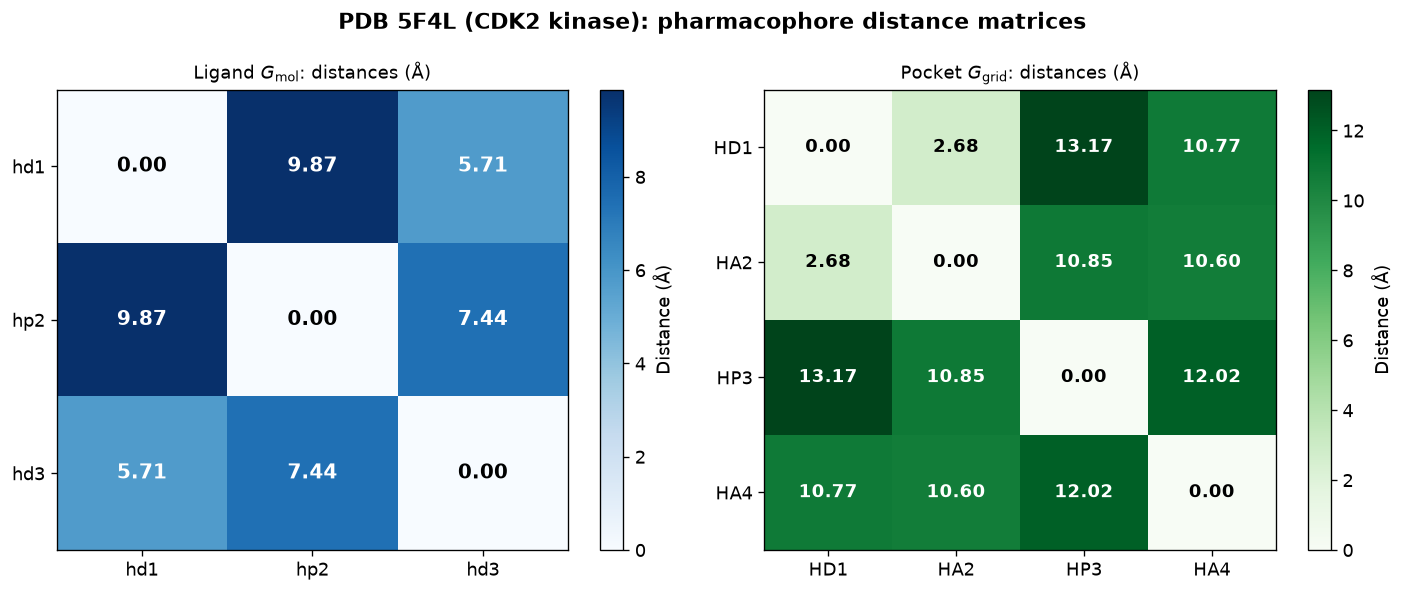

In [11]:
# PDB 5F4L: CDK2 kinase complex, 12-qubit instance
# Data: pharmacophore distances from the data set of Ding et al. [6], as provided in the
#       repository github.com/25benjaminli/molecular-docking-qaoa
# Formulation: geometric QUBO of Triuzzi et al. [1]
#
# Ligand pharmacophore points: hd1 (H-bond donor), hp2 (hydrophobic), hd3 (H-bond donor)
# Pocket pharmacophore points: HD1 (H-bond donor), HA2 (H-bond acceptor),
#                              HP3 (hydrophobic), HA4 (H-bond acceptor)
# The optimal mapping is not known in advance and is determined by exhaustive search in Section 3.

# Ligand inter-point distances (Angstrom)
W_mol = np.array([
    [0.00, 9.87, 5.71],
    [9.87, 0.00, 7.44],
    [5.71, 7.44, 0.00]
])
atom_names = ['hd1', 'hp2', 'hd3']
N_mol = 3

# Pocket inter-point distances (Angstrom)
W_grid = np.array([
    [ 0.00,  2.68, 13.17, 10.77],
    [ 2.68,  0.00, 10.85, 10.60],
    [13.17, 10.85,  0.00, 12.02],
    [10.77, 10.60, 12.02,  0.00]
])
pocket_names = ['HD1', 'HA2', 'HP3', 'HA4']
N_grid = 4

n_vars = N_mol * N_grid  # 12 binary variables = 12 qubits
dim    = 2**n_vars        # 4096 basis states
n_feasible = int(np.prod(np.arange(N_grid - N_mol + 1, N_grid + 1)))   # P(N_grid, N_mol)

print('=== Molecular Docking: PDB 5F4L (CDK2 kinase) ===')
print(f'Ligand pharmacophore points: {N_mol} ({", ".join(atom_names)})')
print(f'Pocket pharmacophore points: {N_grid} ({", ".join(pocket_names)})')
print(f'Binary variables: {N_mol} x {N_grid} = {n_vars} qubits')
print(f'Hilbert space: 2^{n_vars} = {dim} states')
print(f'Valid permutations: P({N_grid},{N_mol}) = {n_feasible}')
print()
print('Ligand inter-point distances (Angstrom):')
for i, name in enumerate(atom_names):
    for j, name2 in enumerate(atom_names):
        if j > i:
            print(f'  {name}-{name2}: {W_mol[i,j]:.2f} Å')
print()
print('Protein pocket distances (Angstrom):')
for i, name in enumerate(pocket_names):
    for j, name2 in enumerate(pocket_names):
        if j > i:
            print(f'  {name}-{name2}: {W_grid[i,j]:.2f} Å')

# Visualization: distance matrices as heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('PDB 5F4L (CDK2 kinase): pharmacophore distance matrices',
             fontsize=13, fontweight='bold')

im1 = axes[0].imshow(W_mol, cmap='Blues', aspect='auto')
axes[0].set_xticks(range(N_mol)); axes[0].set_yticks(range(N_mol))
axes[0].set_xticklabels(atom_names); axes[0].set_yticklabels(atom_names)
axes[0].set_title(r'Ligand $G_{\mathrm{mol}}$: distances (Å)', fontsize=11)
for i in range(N_mol):
    for j in range(N_mol):
        axes[0].text(j, i, f'{W_mol[i,j]:.2f}', ha='center', va='center',
                    fontsize=12, fontweight='bold',
                    color='white' if W_mol[i,j] > 5 else 'black')
plt.colorbar(im1, ax=axes[0], label='Distance (Å)')

im2 = axes[1].imshow(W_grid, cmap='Greens', aspect='auto')
axes[1].set_xticks(range(N_grid)); axes[1].set_yticks(range(N_grid))
axes[1].set_xticklabels(pocket_names); axes[1].set_yticklabels(pocket_names)
axes[1].set_title(r'Pocket $G_{\mathrm{grid}}$: distances (Å)', fontsize=11)
for i in range(N_grid):
    for j in range(N_grid):
        axes[1].text(j, i, f'{W_grid[i,j]:.2f}', ha='center', va='center',
                    fontsize=11, fontweight='bold',
                    color='white' if W_grid[i,j] > 8 else 'black')
plt.colorbar(im2, ax=axes[1], label='Distance (Å)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'docking_setup_5f4l.png'), dpi=150, bbox_inches='tight')
plt.show()

## 2. QUBO construction

Following Eqs. (9) to (13) of [1], the cost function is $H = A\, H_{\text{pen}} + H_{\text{opt}}$. The penalty term enforces two constraints. The first requires each ligand point to be placed exactly once, $\sum_{i'} x_{i,i'} = 1$. Expanding $(1 - \sum_{i'} x_{i,i'})^2$ and dropping the constant gives diagonal terms $-1$ and off-diagonal terms $+2$ between variables of the same ligand point. The second requires each pocket point to host at most one ligand point, and is enforced by a term $+2$ for every pair of ligand points placed on the same pocket point.

The penalty weight must be large enough that no constraint violation lowers the energy below the optimal feasible value. Since the distances of a real instance can take any scale, we set it proportional to the largest objective coefficient, $A = 3.5 \max|Q_{\text{opt}}|$. Unlike in the toy problem, the optimal mapping has a non-zero distortion, so there is a finite minimum value of $A$ below which an infeasible state becomes the ground state of the QUBO. Section 8 computes this value and shows that the choice of $A$ strongly affects the behaviour of QAOA.

Finally, the QUBO matrix is divided by its largest absolute entry, so that all coefficients lie in $[-1, 1]$. A rescaling of the cost function by a constant $c$ is equivalent to a rescaling of the angles $\gamma$ by $c$, so the normalisation fixes the range of $\gamma$ that the classical optimiser has to explore.

In [12]:
def vidx(i, ip):
    """Flat index for binary variable x_{i, ip} (atom i -> grid point ip)."""
    return i * N_grid + ip

def build_docking_qubo(W_mol, W_grid):
    n = N_mol * N_grid
    Q_opt = np.zeros((n, n))
    Q_pen = np.zeros((n, n))

    # Objective: minimize geometric distortion between ligand and pocket (eq. 9)
    for i in range(N_mol):
        for j in range(i + 1, N_mol):
            for ip in range(N_grid):
                for jp in range(N_grid):
                    if ip == jp:
                        continue
                    coeff = (W_mol[i, j] - W_grid[ip, jp])**2
                    k1, k2 = vidx(i, ip), vidx(j, jp)
                    r, c = min(k1, k2), max(k1, k2)
                    Q_opt[r, c] += coeff

    # Penalty 1: each atom maps to exactly one grid point (eq. 10)
    for i in range(N_mol):
        for ip in range(N_grid):
            Q_pen[vidx(i, ip), vidx(i, ip)] -= 1.0
        for ip in range(N_grid):
            for jp in range(ip + 1, N_grid):
                Q_pen[vidx(i, ip), vidx(i, jp)] += 2.0

    # Penalty 2: each grid point hosts at most one atom (eq. 11)
    for ip in range(N_grid):
        for i in range(N_mol):
            for j in range(i + 1, N_mol):
                Q_pen[vidx(i, ip), vidx(j, ip)] += 2.0

    # Penalty strength: A = 3.5 * max|Q_opt|, i.e. proportional to the scale of the objective
    # (see Section 2 and, for its effect on QAOA, Section 8)
    max_obj = np.max(np.abs(Q_opt))
    A = 3.5 * max(max_obj, 1e-10)
    Q_final = A * Q_pen + Q_opt

    # Normalize to [-1, 1] for numerical stability of QAOA rotation angles
    max_val = np.max(np.abs(Q_final))
    if max_val > 1e-10:
        Q_final = Q_final / max_val
    return Q_final, A

def qe(x, Q):
    """QUBO energy of bitstring x."""
    return float(x @ Q @ x)

def is_valid(x):
    """Check that x encodes a valid injective mapping (one atom per grid point)."""
    X = np.array(x).reshape(N_mol, N_grid)
    return np.all(X.sum(axis=1) == 1) and np.all(X.sum(axis=0) <= 1)

def decode(x):
    """Decode bitstring x into atom -> grid point mapping."""
    X = np.array(x).reshape(N_mol, N_grid)
    return {i: int(np.argmax(X[i])) for i in range(N_mol) if X[i].sum() == 1}

Q, A_penalty = build_docking_qubo(W_mol, W_grid)

# Precompute energies for all 2^12 = 4096 basis states
all_energies = np.zeros(dim)
all_bits = np.zeros((dim, n_vars), dtype=int)
for idx in range(dim):
    b = np.array([(idx >> (n_vars - 1 - k)) & 1 for k in range(n_vars)], dtype=float)
    all_bits[idx] = b.astype(int)
    all_energies[idx] = qe(b, Q)

min_e = min(all_energies)
min_positions = [i for i, e in enumerate(all_energies) if abs(e - min_e) < 1e-10]
print(f"Minimum energy: {min_e:.6f}, found at {len(min_positions)} state(s): {min_positions}")
for pos in min_positions:
    print(f"  idx={pos}, mapping={decode(all_bits[pos])}, valid={is_valid(all_bits[pos])}")

print(f'QUBO: {n_vars}x{n_vars}, penalty A={A_penalty:.2f}')
print(f'QUBO density: {np.sum(Q != 0) / n_vars**2 * 100:.1f}%')

Minimum energy: -1.448721, found at 1 state(s): [2068]
  idx=2068, mapping={0: 0, 1: 3, 2: 1}, valid=True
QUBO: 12x12, penalty A=194.78
QUBO density: 54.2%


## 3. Classical baselines

With $N_{\text{mol}} = 3$ and $N_{\text{grid}} = 4$ there are $P(4,3) = 24$ feasible mappings, and exhaustive enumeration is immediate. It determines the optimal mapping, which is not known in advance for this instance, and provides the reference solution for all other methods.

Simulated annealing (SA) is included as the standard classical heuristic for QUBO problems, although at this size it is not needed. It acts on the full set of $2^{12} = 4096$ bitstrings, including the 4072 infeasible ones, with single bit-flip moves and a geometric cooling schedule, and relies on the penalty terms to steer the walk towards feasible states. We report the fraction of 50 independent runs that reach the optimum.

In [13]:
# Brute force: enumerate all P(N_grid, N_mol) = 4!/(4-3)! = 24 valid injective mappings
best_bf = np.inf; bf_x = None; all_bf = []
for perm in permutations(range(N_grid), N_mol):
    x = np.zeros(n_vars)
    for i, ip in enumerate(perm): x[vidx(i, ip)] = 1
    e = qe(x, Q)
    all_bf.append((dict(enumerate(perm)), e))
    if e < best_bf: best_bf, bf_x, bf_mapping = e, x.copy(), dict(enumerate(perm))
all_bf.sort(key=lambda r: r[1])

print(f'Brute force: {len(all_bf)} mappings evaluated')
print(f'Optimal mapping: {bf_mapping}, energy: {best_bf:.4f}')

# SA: bit-flip moves, explores full space
def run_sa(n_epochs=1000, T_start=15.0, T_end=0.01):
    x = np.random.randint(0, 2, n_vars).astype(float)
    E = qe(x, Q); best_x, best_E = x.copy(), E
    cool = (T_end / T_start)**(1 / n_epochs); T = T_start
    for _ in range(n_epochs):
        flip_idx = np.random.choice(n_vars)
        xn = x.copy(); xn[flip_idx] = 1 - xn[flip_idx]
        En = qe(xn, Q); dE = En - E
        if dE < 0 or np.random.random() < np.exp(-dE / T):
            x, E = xn, En
            if E < best_E: best_E, best_x = E, x.copy()
        T *= cool
    return best_x, best_E

sa_energies = []; t0 = time.time()
n_runs = 50
for _ in range(n_runs): _, e = run_sa(); sa_energies.append(e)
t_sa = time.time() - t0
sa_best = min(sa_energies)
sa_success = sum(abs(e - best_bf) < 0.01 for e in sa_energies) / n_runs
print(f'\nSimulated Annealing ({n_runs} runs, {t_sa:.2f}s): best={sa_best:.4f}, success={sa_success*100:.0f}%')

sa_best_x, sa_best_e = run_sa()
print(f"SA best energy: {sa_best_e:.4f}")
print(f"SA best valid: {is_valid(sa_best_x)}")
print(f"SA best mapping: {decode(sa_best_x)}")
print(f"Hamming weight: {int(sa_best_x.sum())}")

Brute force: 24 mappings evaluated
Optimal mapping: {0: 0, 1: 3, 2: 1}, energy: -1.4487

Simulated Annealing (50 runs, 1.88s): best=-1.4487, success=66%
SA best energy: -1.4487
SA best valid: True
SA best mapping: {0: 0, 1: 3, 2: 1}
Hamming weight: 3


The optimal mapping places hd1 on HD1, hp2 on HA4 and hd3 on HA2. As anticipated in Section 1, it pairs the ligand donor hd1 with the pocket donor HD1 and the hydrophobic centre hp2 with an acceptor, which are not favourable interactions: it is the best geometric match among the 24 mappings, not a validated binding pose. Simulated annealing reaches it in about two thirds of the runs.

## 4. QAOA with the RX mixer

QAOA [3] prepares the state

$$|\psi(\boldsymbol{\gamma}, \boldsymbol{\beta})\rangle = U_B(\beta_p)\, U_C(\gamma_p) \cdots U_B(\beta_1)\, U_C(\gamma_1)\, |+\rangle^{\otimes n}$$

and minimises the expectation value $\langle \psi | H | \psi \rangle$ over the $2p$ angles. The cost unitary $U_C(\gamma) = e^{-i\gamma H}$ is diagonal in the computational basis, so in the simulation it is applied exactly as a phase on each amplitude; on hardware it would have to be compiled into single- and two-qubit gates. The simulation also gives direct access to the probability $P(\text{opt})$ of the optimal bitstring and to the probability $P(\text{valid})$ of the feasible subspace, which on hardware would have to be estimated from samples.

The standard mixer $U_B(\beta) = e^{-i\beta \sum_k X_k}$ applies the same rotation to every qubit. It does not respect the constraints and moves amplitude freely between feasible and infeasible states.

The angles are optimised with COBYLA, a gradient-free method, from random initial points in $[0, \pi]$. The number of restarts and the maximum number of iterations increase with $p$: 30 restarts and 500 iterations for $p \le 3$, 80 and 1000 for $p = 5$, 150 and 2000 for $p \ge 8$. The comparison between depths is therefore not at a fixed computational budget, but an estimate of what each depth can achieve with a reasonable optimisation effort.

In [14]:
def apply_cost(state, gamma):
    """Cost unitary U_C(gamma) = exp(-i*gamma*H_QUBO).
    Exact for diagonal H: multiply each amplitude by a phase."""
    return state * np.exp(-1j * gamma * all_energies)

def apply_mixer_rx(state, beta):
    """Standard RX mixer U_B(beta) = exp(-i*beta*sum_k X_k).
    Vectorized via NumPy tensor manipulation (~60x speedup over naive loop).
    Does NOT preserve the valid-mapping subspace."""
    cb, sb = np.cos(beta), np.sin(beta)
    state_tensor = state.reshape([2] * n_vars)
    for q in range(n_vars):
        state_tensor = np.swapaxes(state_tensor, 0, q)
        a0 = state_tensor[0].copy()
        a1 = state_tensor[1].copy()
        state_tensor[0] = cb * a0 - 1j * sb * a1
        state_tensor[1] = cb * a1 - 1j * sb * a0
        state_tensor = np.swapaxes(state_tensor, 0, q)
    return state_tensor.flatten()

#NOTE
#Equivalent naive implementation (readable but slow):
#
#        cb, sb = np.cos(beta), np.sin(beta)
#        for q in range(n_vars):
#            new_state = np.zeros_like(state)
#            for idx in range(dim):
#                idx_flipped = idx ^ (1 << (n_vars - 1 - q))
#                new_state[idx] = cb * state[idx] - 1j * sb * state[idx_flipped]
#            state = new_state
#
#    For each qubit q, every basis state |idx⟩ mixes with its partner |idx_flipped⟩
#    (identical except for bit q), applying [[cb, -i·sb], [-i·sb, cb]] to each pair.


def run_qaoa_rx(params):
    """QAOA with RX mixer. Initial state: uniform superposition over all 4096 states."""
    p = len(params) // 2
    state = np.ones(dim, dtype=complex) / np.sqrt(dim)
    for l in range(p):
        state = apply_cost(state, params[2*l])
        state = apply_mixer_rx(state, params[2*l+1])
    probs = np.abs(state)**2
    return float(np.dot(probs, all_energies)), probs

def qaoa_obj_rx(params): return run_qaoa_rx(params)[0]

# Optimization hyperparameters — scaled with p
def get_opt_params(p):  
    n_restarts = 30 if p <= 3 else 80 if p <= 5 else 150
    rhobeg     = 0.5 if p <= 3 else 0.3
    maxiter    = 500 if p <= 3 else 1000 if p <= 5 else 2000
    return n_restarts, rhobeg, maxiter

print('Running QAOA with RX mixer...')
opt_idx = int(''.join(map(str, bf_x.astype(int))), 2)
p_list_qaoa = [1, 2, 3, 5, 8, 10]
config_rx = {'problem': problem_fingerprint(Q), 'p_list': p_list_qaoa,
             'opt_params': [get_opt_params(p) for p in p_list_qaoa]}
ck = load_checkpoint('qaoa_rx', config_rx)
qaoa_rx_results = ck['results'] if ck else {}
if ck:
    np.random.set_state(ck['rng_state'])

for p in p_list_qaoa:
    n_restarts, rhobeg, maxiter = get_opt_params(p)
    if p in qaoa_rx_results:
        r = qaoa_rx_results[p]
        print(f'  p={p} ({2*p} params, {n_restarts} restarts): E={r["energy"]:.4f}, '
              f'P(opt)={r["p_opt"]:.3f}, P(valid)={r["p_val"]:.3f}, t={r["time"]:.1f}s [checkpoint]')
        continue
    best_e, best_par = np.inf, None; t0 = time.time()
    for _ in range(n_restarts):
        x0 = np.random.uniform(0, np.pi, 2*p)
        res = minimize(qaoa_obj_rx, x0, method='COBYLA',
                       options={'maxiter': maxiter, 'rhobeg': rhobeg})
        if res.fun < best_e: best_e, best_par = res.fun, res.x
    _, probs = run_qaoa_rx(best_par)
    p_opt = probs[opt_idx]
    p_val = sum(probs[i] for i in range(dim) if is_valid(all_bits[i]))
    qaoa_rx_results[p] = {'energy': best_e, 'params': best_par,
                           'p_opt': p_opt, 'p_val': p_val, 'time': time.time() - t0}
    save_checkpoint('qaoa_rx', config_rx, qaoa_rx_results, np.random.get_state())
    print(f'  p={p} ({2*p} params, {n_restarts} restarts): '
          f'E={best_e:.4f}, P(opt)={p_opt:.3f}, P(valid)={p_val:.3f}, '
          f't={time.time()-t0:.1f}s')

print(f'Optimal (brute force): {best_bf:.4f}')

Running QAOA with RX mixer...
  p=1 (2 params, 30 restarts): E=-0.4439, P(opt)=0.005, P(valid)=0.104, t=2.5s [checkpoint]
  p=2 (4 params, 30 restarts): E=-0.8116, P(opt)=0.014, P(valid)=0.323, t=16.1s [checkpoint]
  p=3 (6 params, 30 restarts): E=-0.8891, P(opt)=0.020, P(valid)=0.454, t=35.8s [checkpoint]
  p=5 (10 params, 80 restarts): E=-1.2140, P(opt)=0.036, P(valid)=0.833, t=313.3s [checkpoint]
  p=8 (16 params, 150 restarts): E=-1.2690, P(opt)=0.036, P(valid)=0.917, t=1740.0s [checkpoint]
  p=10 (20 params, 150 restarts): E=-1.2751, P(opt)=0.038, P(valid)=0.903, t=2516.1s [checkpoint]
Optimal (brute force): -1.4487


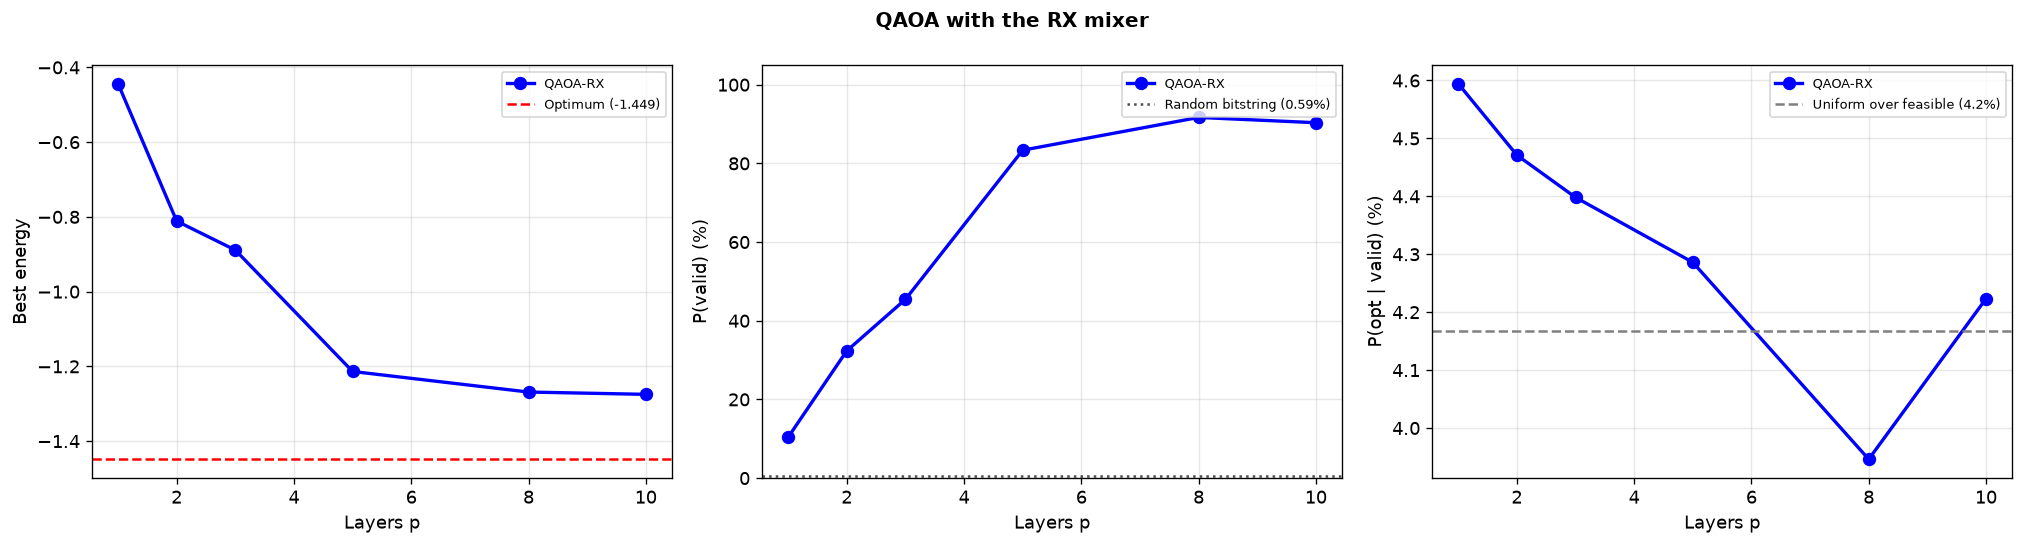

In [15]:
plot_depth_panels([('QAOA-RX', qaoa_rx_results, 'bo-')],
                  'QAOA with the RX mixer', 'fig_qaoa_rx_5f4l.png')

*Figure 2. QAOA-RX on 5F4L: best energy, probability of the feasible subspace and probability of the optimum within the feasible subspace, as functions of the number of layers.*

$P(\text{valid})$ increases from about 10% at $p = 1$ to about 90% at $p = 8$ and $p = 10$. A random bitstring is feasible with probability $24/4096 \approx 0.59\%$, so the circuit concentrates most of the amplitude in a very small part of the Hilbert space, about 150 times the random value.

Within the feasible subspace, however, the circuit hardly discriminates between mappings. The conditional probability $P(\text{opt} \mid \text{valid}) = P(\text{opt})/P(\text{valid})$, computed in Section 5, remains between 4.0% and 4.6%, close to the uniform value $1/24 \approx 4.2\%$, at every depth. As in the toy problem, the RX ansatz learns where the feasible states are, but not which feasible state is optimal. Section 8 relates this behaviour to the energy scale of the penalty term.

## 5. QAOA with the XY mixer

The XY mixer [2] acts on pairs of qubits that belong to the same ligand point,

$$U_{XY}(\beta) = \prod_{i} \prod_{p < q} e^{-i\beta\,(X_{ip}X_{iq} + Y_{ip}Y_{iq})/2}.$$

On each pair it leaves $|00\rangle$ and $|11\rangle$ unchanged and acts within the subspace spanned by $|01\rangle$ and $|10\rangle$:

$$|01\rangle \to \cos\beta\, |01\rangle - i\sin\beta\, |10\rangle, \qquad |10\rangle \to -i\sin\beta\, |01\rangle + \cos\beta\, |10\rangle.$$

The mixer therefore preserves the Hamming weight of each row of the assignment matrix, and with it the constraint that each ligand point is placed exactly once. The initial state is the uniform superposition of the 24 feasible mappings, which satisfies this constraint.

The mixer does not preserve the second constraint. Two ligand points can be moved onto the same pocket point, so amplitude can leak from the 24 feasible states into the larger subspace of $4^3 = 64$ states with one placement per ligand point, where injectivity is enforced only by the penalty. A mixer that also preserves injectivity would have to act on several rows at once, as the permutation mixers discussed in [2].

Both mixers are optimised with the same hyperparameters.

In [16]:
def apply_mixer_xy(state, beta):
    """XY mixer: exp(-i*beta*(XX+YY)/2) on each pair (x_{i,p}, x_{i,q}).
    Implementation: move target qubit pair to last two axes, apply 4x4 matrix, restore."""
    cb, sb = np.cos(beta), np.sin(beta)
    xy_mat = np.array([
        [1,  0,       0,       0],
        [0,  cb,      -1j*sb,  0],
        [0,  -1j*sb,  cb,      0],
        [0,  0,       0,       1]
    ], dtype=complex)

    for i in range(N_mol):
        for p in range(N_grid):
            for q in range(p + 1, N_grid):
                q0 = vidx(i, p)
                q1 = vidx(i, q)
                axes = list(range(n_vars))
                axes.remove(q0); axes.remove(q1)
                axes = axes + [q0, q1]
                st = state.reshape([2]*n_vars).transpose(axes)
                orig_shape = st.shape
                st_flat = st.reshape(-1, 4)
                st_flat = st_flat @ xy_mat.T
                st = st_flat.reshape(orig_shape)
                inv_axes = [0] * n_vars
                for new, old in enumerate(axes):
                    inv_axes[old] = new
                state = st.transpose(inv_axes).reshape(dim)
    return state

#NOTE
# Equivalent naive implementation (readable but slow):
#for i in range(N_mol):
#    for p in range(N_grid):
#        for q in range(p + 1, N_grid):
#            q0, q1 = vidx(i, p), vidx(i, q)
#            
#            new_state = np.zeros_like(state)
#            
#            for idx in range(dim):
#                b0 = (idx >> (n_vars - 1 - q0)) & 1
#                b1 = (idx >> (n_vars - 1 - q1)) & 1
#                
#                if b0 + b1 == 1:  
#                    idx_swap = idx ^ (1 << (n_vars-1-q0)) ^ (1 << (n_vars-1-q1))
#                    # 'state' is not modified inside the idx loop, so it can be used to fill 'new_state'
#                    new_state[idx] = cb * state[idx] - 1j * sb * state[idx_swap]
#                else:             
#                    new_state[idx] = state[idx]
#            
#            state = new_state

def run_qaoa_xy(params):
    """QAOA with XY mixer.
    Initial state: uniform superposition over 24 valid permutations only."""
    p = len(params) // 2
    state = np.zeros(dim, dtype=complex)
    for mapping, _ in all_bf:
        x = np.zeros(n_vars)
        for i, ip in mapping.items(): x[vidx(i, ip)] = 1
        idx = int(''.join(map(str, x.astype(int))), 2)
        state[idx] = 1.0
    state /= np.linalg.norm(state)
    for l in range(p):
        state = apply_cost(state, params[2*l])
        state = apply_mixer_xy(state, params[2*l+1])
    probs = np.abs(state)**2
    return float(np.dot(probs, all_energies)), probs

def qaoa_obj_xy(params): return run_qaoa_xy(params)[0]

print('Running QAOA with XY mixer...')
print('(Same hyperparameters as RX for fair comparison)')
config_xy = {'problem': problem_fingerprint(Q), 'p_list': p_list_qaoa,
             'opt_params': [get_opt_params(p) for p in p_list_qaoa]}
ck = load_checkpoint('qaoa_xy', config_xy)
qaoa_xy_results = ck['results'] if ck else {}
if ck:
    np.random.set_state(ck['rng_state'])

for p in p_list_qaoa:
    n_restarts, rhobeg, maxiter = get_opt_params(p)
    if p in qaoa_xy_results:
        r = qaoa_xy_results[p]
        print(f'  p={p} ({2*p} params): E={r["energy"]:.4f}, P(opt)={r["p_opt"]:.3f}, '
              f'P(valid)={r["p_val"]:.3f}, t={r["time"]:.1f}s [checkpoint]')
        continue
    best_e, best_par = np.inf, None; t0 = time.time()
    for _ in range(n_restarts):
        x0 = np.random.uniform(0, np.pi, 2*p)
        res = minimize(qaoa_obj_xy, x0, method='COBYLA',
                       options={'maxiter': maxiter, 'rhobeg': rhobeg})
        if res.fun < best_e: best_e, best_par = res.fun, res.x
    _, probs = run_qaoa_xy(best_par)
    p_opt = probs[opt_idx]
    p_val = sum(probs[i] for i in range(dim) if is_valid(all_bits[i]))
    qaoa_xy_results[p] = {'energy': best_e, 'params': best_par,
                           'p_opt': p_opt, 'p_val': p_val, 'time': time.time() - t0}
    save_checkpoint('qaoa_xy', config_xy, qaoa_xy_results, np.random.get_state())
    print(f'  p={p} ({2*p} params): E={best_e:.4f}, P(opt)={p_opt:.3f}, '
          f'P(valid)={p_val:.3f}, t={time.time()-t0:.1f}s')

print(f'Optimal (brute force): {best_bf:.4f}')

Running QAOA with XY mixer...
(Same hyperparameters as RX for fair comparison)
  p=1 (2 params): E=-1.3463, P(opt)=0.042, P(valid)=1.000, t=2.2s [checkpoint]
  p=2 (4 params): E=-1.3465, P(opt)=0.042, P(valid)=1.000, t=10.1s [checkpoint]
  p=3 (6 params): E=-1.3493, P(opt)=0.068, P(valid)=0.999, t=39.0s [checkpoint]
  p=5 (10 params): E=-1.3517, P(opt)=0.048, P(valid)=0.998, t=511.7s [checkpoint]
  p=8 (16 params): E=-1.3110, P(opt)=0.042, P(valid)=0.958, t=3010.8s [checkpoint]
  p=10 (20 params): E=-1.2815, P(opt)=0.045, P(valid)=0.932, t=3343.0s
Optimal (brute force): -1.4487


In [17]:
# Does the XY mixer improve optimization within the valid subspace?
# P(opt|valid) = P(opt) / P(valid) — conditional probability of finding optimum
# given that a valid mapping was found.
print('P(opt | valid) = P(opt) / P(valid):')
print('Does structured mixer improve exploration within the feasible subspace?')
print()
print(f'{"p":<4} {"RX P(opt|val)":>15} {"XY P(opt|val)":>15} {"XY/RX":>8}')
print('-' * 45)
for p in [1, 2, 3, 5, 8,10]: 
    rx = qaoa_rx_results[p]
    xy = qaoa_xy_results[p]
    rx_cond = rx['p_opt'] / rx['p_val'] if rx['p_val'] > 0 else 0
    xy_cond = xy['p_opt'] / xy['p_val'] if xy['p_val'] > 0 else 0
    ratio = xy_cond / rx_cond if rx_cond > 0 else float('inf')
    print(f"p={p:<3} {rx_cond:>15.4f} {xy_cond:>15.4f} {ratio:>7.2f}x")
print(f'Random baseline: {1/24:.4f} ({1/24*100:.1f}%)')

P(opt | valid) = P(opt) / P(valid):
Does structured mixer improve exploration within the feasible subspace?

p      RX P(opt|val)   XY P(opt|val)    XY/RX
---------------------------------------------
p=1            0.0459          0.0421    0.92x
p=2            0.0447          0.0422    0.94x
p=3            0.0440          0.0680    1.55x
p=5            0.0429          0.0483    1.13x
p=8            0.0395          0.0437    1.11x
p=10           0.0422          0.0478    1.13x
Random baseline: 0.0417 (4.2%)


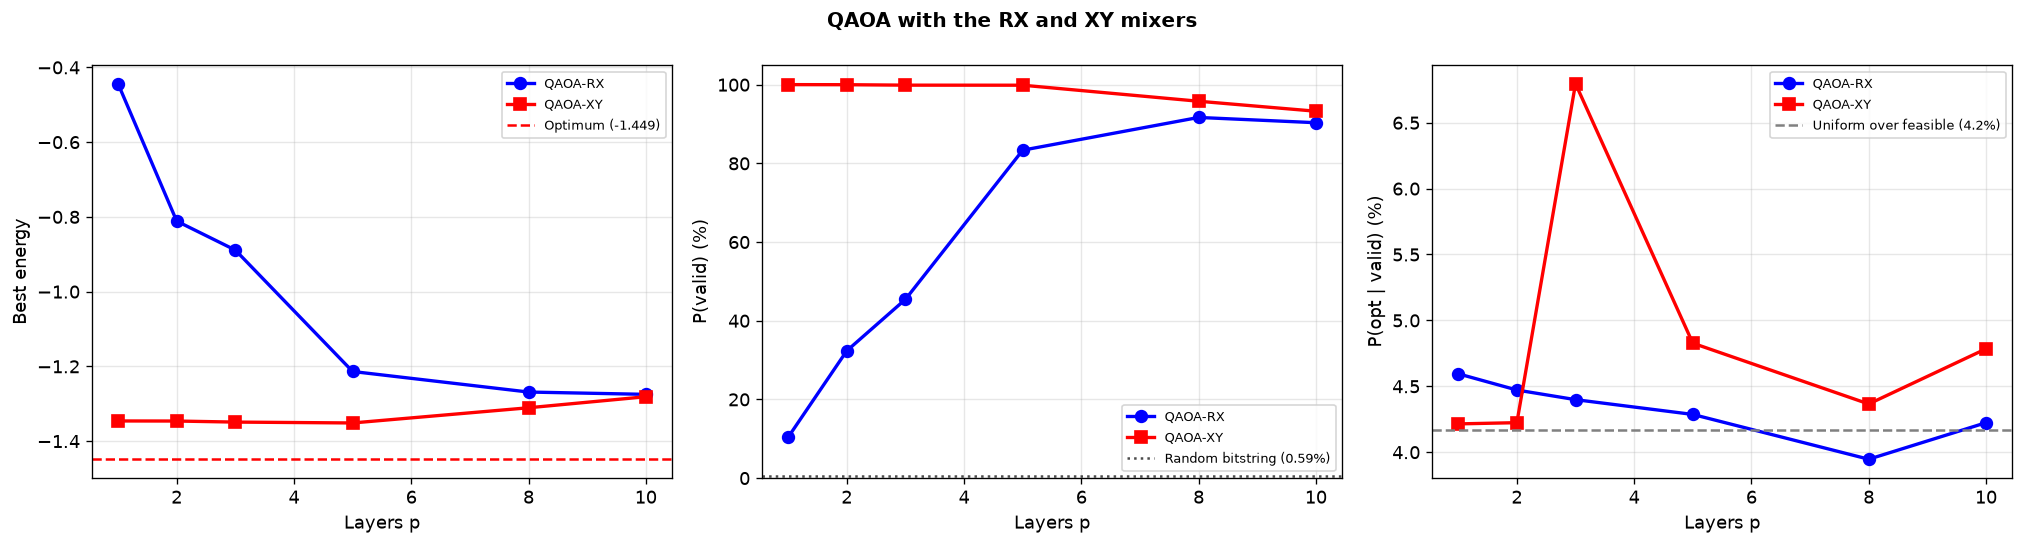

In [18]:
plot_depth_panels([('QAOA-RX', qaoa_rx_results, 'bo-'), ('QAOA-XY', qaoa_xy_results, 'rs-')],
                  'QAOA with the RX and XY mixers', 'fig_qaoa_xy_5f4l.png')

*Figure 3. As Figure 2, comparing the RX and XY mixers.*

The XY ansatz keeps $P(\text{valid})$ at 99.8% or above up to $p = 5$; at $p = 8$ and $p = 10$ it drops to 95.8% and 93.2%, because of the leakage allowed by the mixer. Its selectivity is no better than that of the RX ansatz: $P(\text{opt} \mid \text{valid})$ stays between 4.2% and 4.8% at all depths except $p = 3$, where it reaches 6.8%. The distribution in Figure 5 (bottom right) shows that this value is not a sign of selectivity: at $p = 3$ six mappings, including two of the four with the highest energy, have a probability of about 6.8%, and the other eighteen about 3.3%. The redistribution does not follow the energy ordering.

The energies are even more striking. Between $p = 1$ and $p = 5$ the best energy varies only between $-1.3463$ and $-1.3517$, and at $p = 8$ and $p = 10$ it is higher than at $p = 5$. Since a deeper circuit reproduces any shallower one when the additional angles are set to zero, a higher energy at larger depth shows that the optimiser did not reach the best parameters; it is not a limitation of the ansatz. Section 8 shows that up to $p = 5$ the XY energies remain at the value of the initial state.

## 6. LR-QAOA

In LR-QAOA the $2p$ angles follow a linear schedule determined by two scalars $(\gamma_0, \beta_0)$:

$$\gamma_k = \gamma_0\, \frac{2k-1}{2p}, \qquad \beta_k = \beta_0 \left(1 - \frac{2k-1}{2p}\right), \qquad k = 1, \ldots, p.$$

The schedule resembles a discretised adiabatic evolution, in which the weight of the cost Hamiltonian increases and that of the mixer decreases. The midpoint grid $(2k-1)/(2p)$ avoids $\beta = 0$ in the last layer. In the protocol of [5] the two slopes are fixed in advance; here we optimise them, so the method remains variational, but with two parameters at every depth. This makes it possible to explore much larger depths at a moderate cost. The schedule uses the RX mixer and the same hyperparameters as Section 4.

In [19]:
def run_lr_qaoa(lr_params, p):
    """LR-QAOA: build full 2p-parameter schedule from 2 scalars (gamma0, beta0).
    Uses midpoint grid to avoid beta=0 at last layer."""
    g0, b0 = lr_params
    full = [val for k in range(1, p+1)
            for val in [g0 * (2*k-1) / (2*p), b0 * (1.0 - (2*k-1) / (2*p))]]
    return qaoa_obj_rx(full)

print('Running LR-QAOA (RX mixer, 2 parameters regardless of depth)...')
p_list_lr = [1, 2, 3, 5, 8, 10, 15, 20, 30]   # 2 parameters at every depth: larger p is affordable
config_lr = {'problem': problem_fingerprint(Q), 'p_list': p_list_lr,
             'opt_params': [get_opt_params(p) for p in p_list_lr]}
ck = load_checkpoint('lr_qaoa', config_lr)
lr_results = ck['results'] if ck else {}
if ck:
    np.random.set_state(ck['rng_state'])

for p in p_list_lr:
    n_restarts, rhobeg, maxiter = get_opt_params(p)
    if p in lr_results:
        r = lr_results[p]
        print(f'  p={p} (2 params): E={r["energy"]:.4f}, P(opt)={r["p_opt"]:.3f}, '
              f'P(valid)={r["p_val"]:.3f}, t={r["time"]:.1f}s [checkpoint]')
        continue
    best_e, best_par = np.inf, None; t0 = time.time()
    for _ in range(n_restarts):
        x0 = np.random.uniform(0, np.pi, 2)
        res = minimize(run_lr_qaoa, x0, args=(p,), method='COBYLA',
                       options={'maxiter': maxiter})
        if res.fun < best_e: best_e, best_par = res.fun, res.x
    g0, b0 = best_par
    full = [val for k in range(1, p+1)
            for val in [g0 * (2*k-1) / (2*p), b0 * (1.0 - (2*k-1) / (2*p))]]
    _, probs = run_qaoa_rx(full)
    p_opt = probs[opt_idx]
    p_val = sum(probs[i] for i in range(dim) if is_valid(all_bits[i]))
    lr_results[p] = {'energy': best_e, 'params': best_par,
                     'p_opt': p_opt, 'p_val': p_val, 'time': time.time() - t0}
    save_checkpoint('lr_qaoa', config_lr, lr_results, np.random.get_state())
    print(f'  p={p} (2 params): E={best_e:.4f}, P(opt)={p_opt:.3f}, '
          f'P(valid)={p_val:.3f}, t={time.time()-t0:.1f}s')
print(f'Optimal (brute force): {best_bf:.4f}')    

Running LR-QAOA (RX mixer, 2 parameters regardless of depth)...
  p=1 (2 params): E=-0.4439, P(opt)=0.005, P(valid)=0.104, t=2.8s
  p=2 (2 params): E=-0.6949, P(opt)=0.006, P(valid)=0.126, t=5.3s
  p=3 (2 params): E=-0.7318, P(opt)=0.007, P(valid)=0.130, t=4.4s
  p=5 (2 params): E=-0.8346, P(opt)=0.017, P(valid)=0.348, t=17.5s
  p=8 (2 params): E=-1.1620, P(opt)=0.039, P(valid)=0.766, t=40.5s
  p=10 (2 params): E=-1.2269, P(opt)=0.043, P(valid)=0.841, t=52.8s
  p=15 (2 params): E=-1.2842, P(opt)=0.049, P(valid)=0.900, t=70.0s
  p=20 (2 params): E=-1.3371, P(opt)=0.054, P(valid)=0.973, t=86.6s
  p=30 (2 params): E=-1.3532, P(opt)=0.062, P(valid)=0.986, t=161.2s
Optimal (brute force): -1.4487


In [20]:
print('P(opt | valid) = P(opt) / P(valid):')
print('Mixer and LR-QAOA exploration within the feasible subspace')
print()
print(f'{"p":<4} {"RX P(opt|val)":>15} {"XY P(opt|val)":>15} {"LR P(opt|val)":>15} {"XY/RX":>8} {"LR/RX":>8}')
print('-' * 65)
for p in [1, 2, 3, 5, 8, 10]:
    rx = qaoa_rx_results[p]
    xy = qaoa_xy_results[p]
    lr = lr_results[p]
    rx_cond = rx['p_opt'] / rx['p_val'] if rx['p_val'] > 0 else 0
    xy_cond = xy['p_opt'] / xy['p_val'] if xy['p_val'] > 0 else 0
    lr_cond = lr['p_opt'] / lr['p_val'] if lr['p_val'] > 0 else 0
    xy_rx = xy_cond / rx_cond if rx_cond > 0 else float('inf')
    lr_rx = lr_cond / rx_cond if rx_cond > 0 else float('inf')
    print(f"p={p:<3} {rx_cond:>15.4f} {xy_cond:>15.4f} {lr_cond:>15.4f} {xy_rx:>7.2f}x {lr_rx:>7.2f}x")

print()
print('Large p (LR-QAOA only):')
print(f'{"p":<4} {"LR P(opt|val)":>15}')
print('-' * 22)
for p in [15, 20, 30]:
    lr = lr_results[p]
    lr_cond = lr['p_opt'] / lr['p_val'] if lr['p_val'] > 0 else 0
    print(f"p={p:<3} {lr_cond:>15.4f}")

print(f'\nRandom baseline: {1/24:.4f} ({1/24*100:.1f}%)')

P(opt | valid) = P(opt) / P(valid):
Mixer and LR-QAOA exploration within the feasible subspace

p      RX P(opt|val)   XY P(opt|val)   LR P(opt|val)    XY/RX    LR/RX
-----------------------------------------------------------------
p=1            0.0459          0.0421          0.0459    0.92x    1.00x
p=2            0.0447          0.0422          0.0495    0.94x    1.11x
p=3            0.0440          0.0680          0.0501    1.55x    1.14x
p=5            0.0429          0.0483          0.0497    1.13x    1.16x
p=8            0.0395          0.0437          0.0504    1.11x    1.28x
p=10           0.0422          0.0478          0.0513    1.13x    1.22x

Large p (LR-QAOA only):
p      LR P(opt|val)
----------------------
p=15           0.0544
p=20           0.0558
p=30           0.0632

Random baseline: 0.0417 (4.2%)


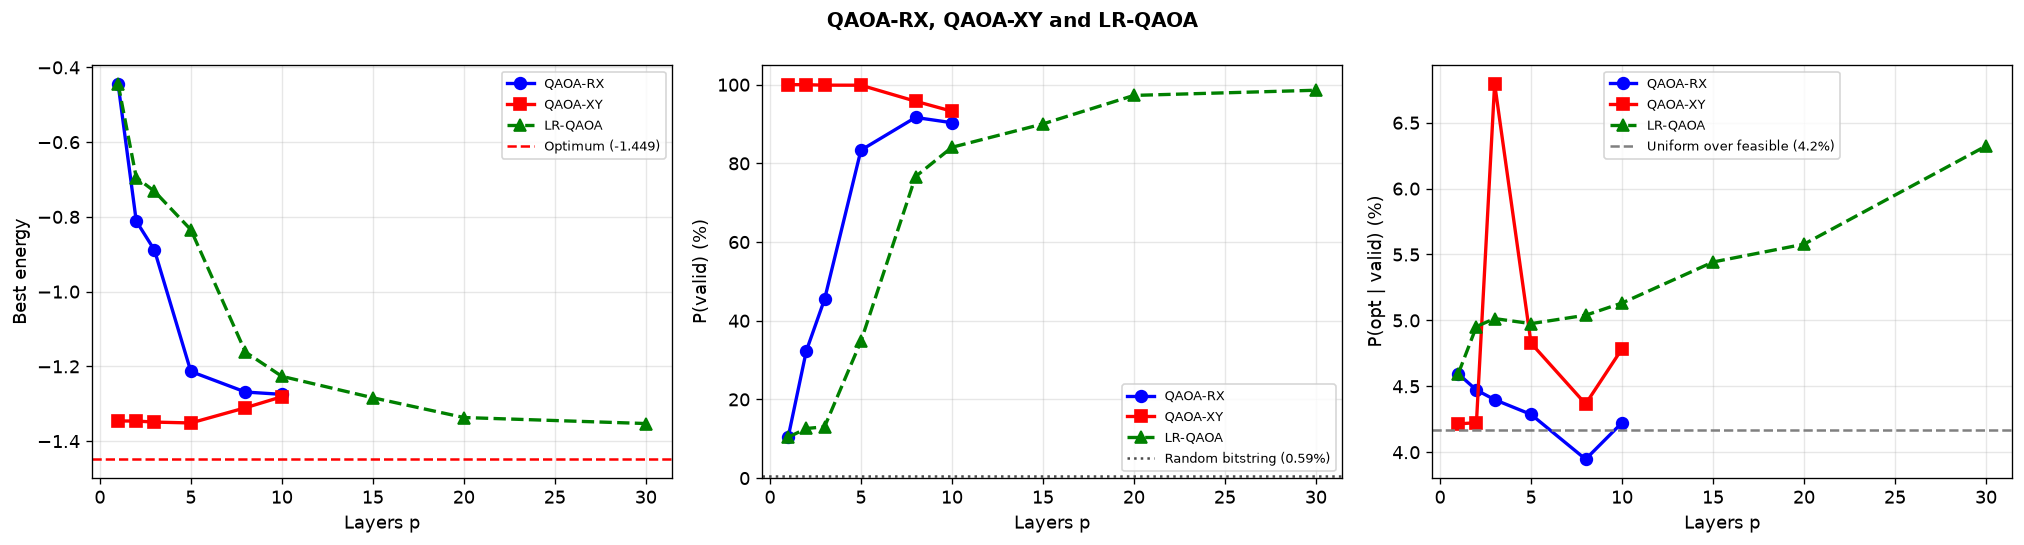

In [21]:
plot_depth_panels([('QAOA-RX', qaoa_rx_results, 'bo-'), ('QAOA-XY', qaoa_xy_results, 'rs-'),
                   ('LR-QAOA', lr_results, 'g^--')],
                  'QAOA-RX, QAOA-XY and LR-QAOA', 'fig_lr_qaoa_5f4l.png')

*Figure 4. As Figure 2, for the three variants. LR-QAOA is shown up to $p = 30$.*

Since the number of parameters is fixed, the cost of LR-QAOA grows only with the depth of the circuit: the run at $p = 30$ takes a few minutes, against about 40 minutes for QAOA-RX at $p = 10$ (see the timings printed above). $P(\text{valid})$ increases steadily with $p$ and exceeds 98% at $p = 30$. $P(\text{opt} \mid \text{valid})$ increases from about 4.6% at $p = 1$ to about 6.3% at $p = 30$, the same values as in the toy problem. The departure from the uniform distribution is modest but systematic. Section 8 shows that it depends strongly on the penalty weight.

## 7. Summary of results

In [22]:
print('=' * 65)
print('MOLECULAR DOCKING: Algorithm Comparison — PDB 5F4L (CDK2 Kinase)')
print('=' * 65)
print(f'{"Algorithm":<36} {"Best E":>8} {"Gap":>8} {"P(opt)":>8}')
print('-' * 65)
print(f'{"Brute Force":<36} {best_bf:>8.4f} {0.0:>8.4f} {"1.000":>8}')
print(f'{"Simulated Annealing":<36} {sa_best:>8.4f} {sa_best-best_bf:>8.4f} {"N/A":>8}')
print()
for p in [1, 2, 3, 5, 8, 10]:
    r = qaoa_rx_results[p]
    label = f'QAOA-RX p={p} ({2*p} params)'
    print(f'{label:<36} {r["energy"]:>8.4f} {r["energy"]-best_bf:>8.4f} {r["p_opt"]:>8.3f}')
print()
for p in [1, 2, 3, 5, 8, 10]:
    r = qaoa_xy_results[p]
    label = f'QAOA-XY p={p} ({2*p} params)'
    print(f'{label:<36} {r["energy"]:>8.4f} {r["energy"]-best_bf:>8.4f} {r["p_opt"]:>8.3f}')
print()
for p in sorted(lr_results):
    r = lr_results[p]
    label = f'LR-QAOA p={p} (2 params)'
    print(f'{label:<36} {r["energy"]:>8.4f} {r["energy"]-best_bf:>8.4f} {r["p_opt"]:>8.3f}')

MOLECULAR DOCKING: Algorithm Comparison — PDB 5F4L (CDK2 Kinase)
Algorithm                              Best E      Gap   P(opt)
-----------------------------------------------------------------
Brute Force                           -1.4487   0.0000    1.000
Simulated Annealing                   -1.4487   0.0000      N/A

QAOA-RX p=1 (2 params)                -0.4439   1.0048    0.005
QAOA-RX p=2 (4 params)                -0.8116   0.6371    0.014
QAOA-RX p=3 (6 params)                -0.8891   0.5596    0.020
QAOA-RX p=5 (10 params)               -1.2140   0.2348    0.036
QAOA-RX p=8 (16 params)               -1.2690   0.1798    0.036
QAOA-RX p=10 (20 params)              -1.2751   0.1736    0.038

QAOA-XY p=1 (2 params)                -1.3463   0.1024    0.042
QAOA-XY p=2 (4 params)                -1.3465   0.1022    0.042
QAOA-XY p=3 (6 params)                -1.3493   0.0994    0.068
QAOA-XY p=5 (10 params)               -1.3517   0.0970    0.048
QAOA-XY p=8 (16 params)            

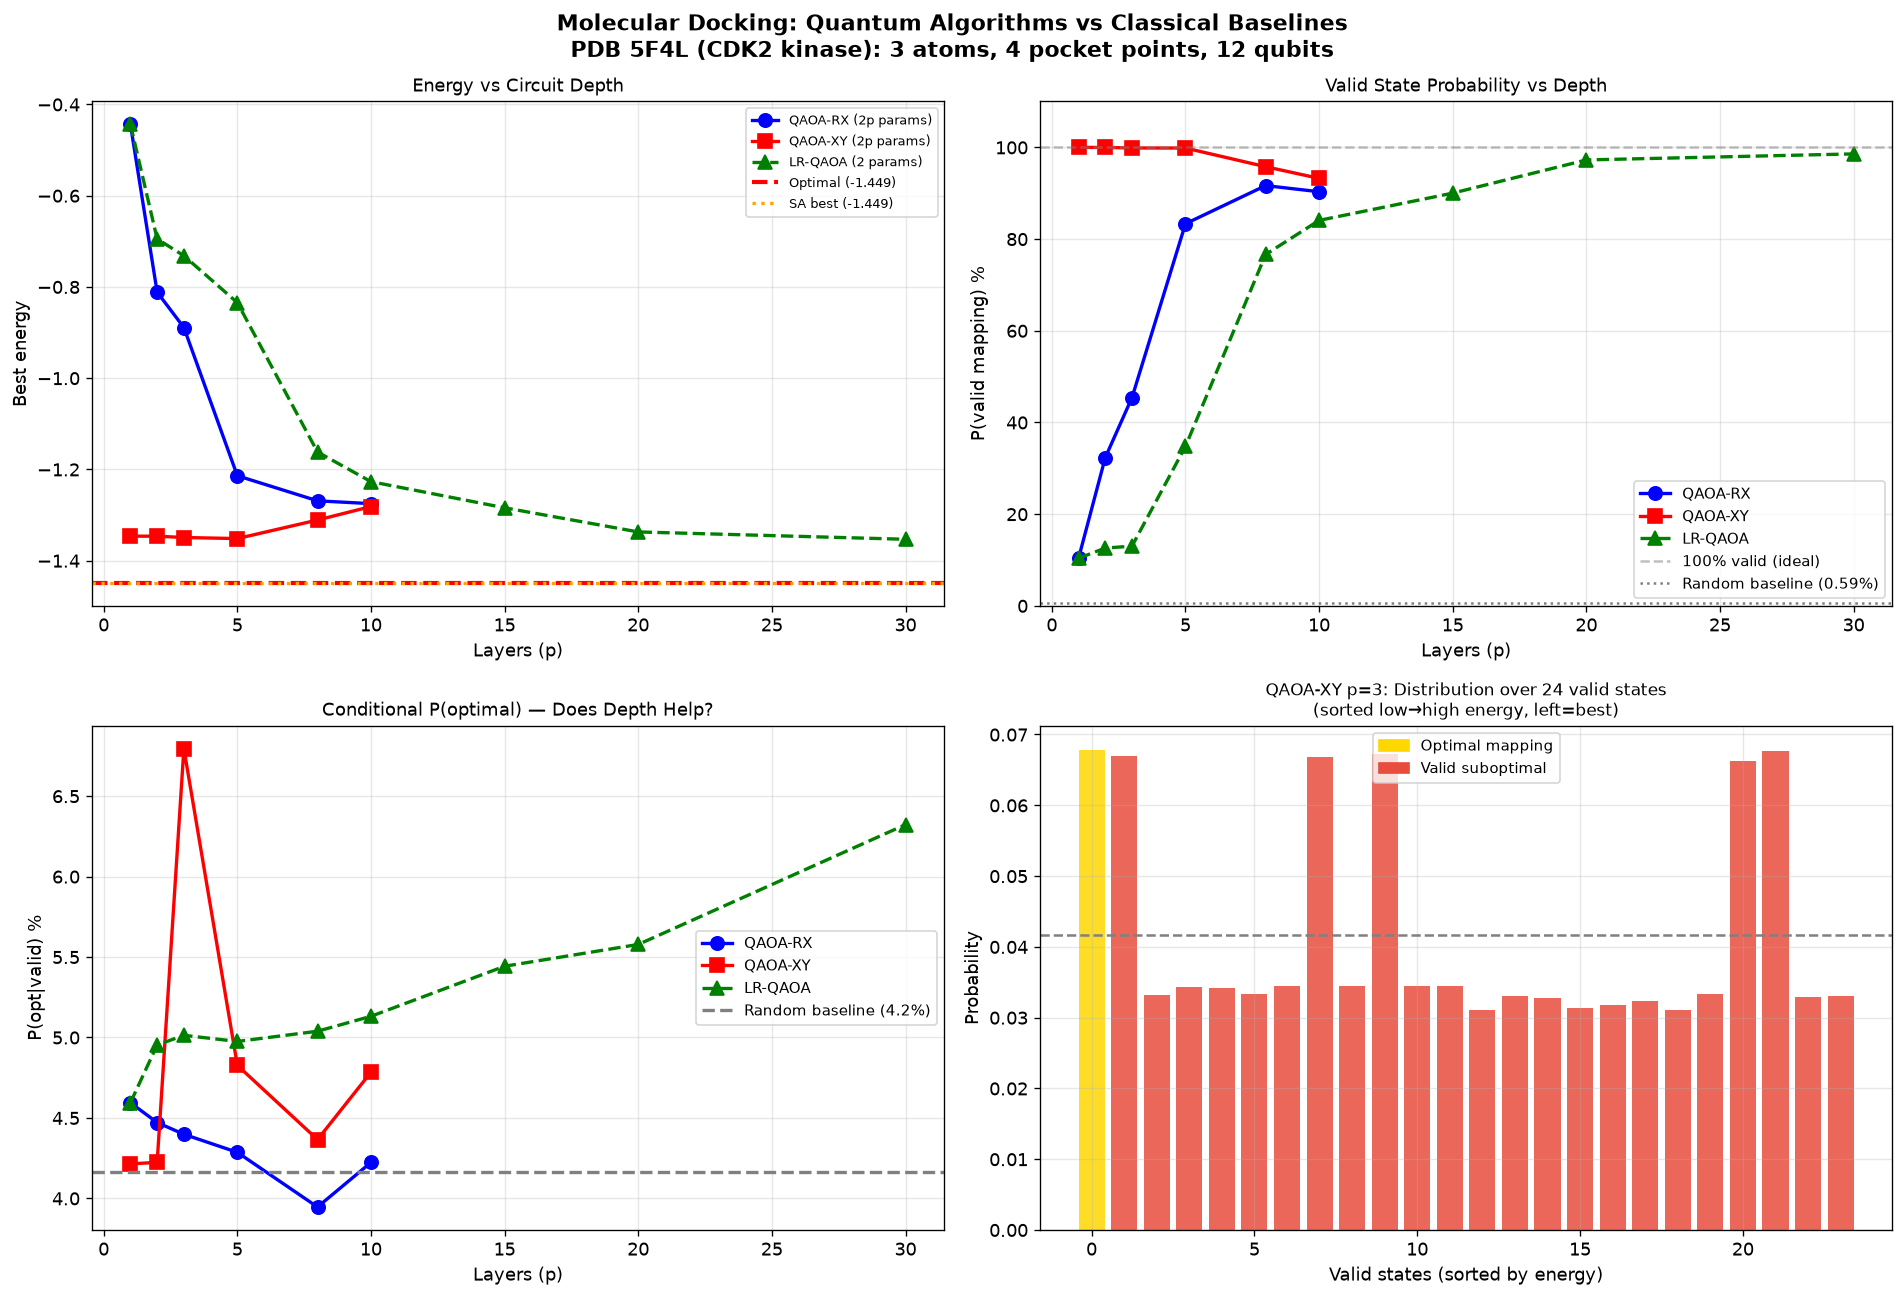

Figure saved: docking_results_5f4l.png


In [23]:
ps_all = [1, 2, 3, 5, 8, 10]
ps_lr  = [1, 2, 3, 5, 8, 10, 15, 20, 30]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Molecular Docking: Quantum Algorithms vs Classical Baselines\n'
             f'PDB 5F4L (CDK2 kinase): {N_mol} atoms, {N_grid} pocket points, {n_vars} qubits',
             fontsize=13, fontweight='bold')

# Top left: energy vs p — all algorithms up to p=30
ax1 = axes[0, 0]
ax1.plot(ps_all, [qaoa_rx_results[p]['energy'] for p in ps_all],
         'bo-', lw=2, ms=8, label='QAOA-RX (2p params)')
ax1.plot(ps_all, [qaoa_xy_results[p]['energy'] for p in ps_all],
         'rs-', lw=2, ms=8, label='QAOA-XY (2p params)')
ax1.plot(ps_lr, [lr_results[p]['energy'] for p in ps_lr],
         'g^--', lw=2, ms=8, label='LR-QAOA (2 params)')
ax1.axhline(y=best_bf, color='red', ls='--', lw=2.5,
            label=f'Optimal ({best_bf:.3f})')
ax1.axhline(y=sa_best, color='orange', ls=':', lw=2,
            label=f'SA best ({sa_best:.3f})')
ax1.set_xlabel('Layers (p)', fontsize=11)
ax1.set_ylabel('Best energy', fontsize=11)
ax1.set_title('Energy vs Circuit Depth', fontsize=11)
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)

# Top right: P(valid) vs p — all three algorithms
ax2 = axes[0, 1]
ax2.plot(ps_all, [qaoa_rx_results[p]['p_val'] * 100 for p in ps_all],
         'bo-', lw=2, ms=8, label='QAOA-RX')
ax2.plot(ps_all, [qaoa_xy_results[p]['p_val'] * 100 for p in ps_all],
         'rs-', lw=2, ms=8, label='QAOA-XY')
ax2.plot(ps_lr, [lr_results[p]['p_val'] * 100 for p in ps_lr],
         'g^--', lw=2, ms=8, label='LR-QAOA')
ax2.axhline(y=100, color='gray', ls='--', alpha=0.5, label='100% valid (ideal)')
ax2.axhline(y=100 * n_feasible / dim, color='black', ls=':', alpha=0.5,
            label=f'Random baseline ({100 * n_feasible / dim:.2f}%)')
ax2.set_xlabel('Layers (p)', fontsize=11)
ax2.set_ylabel('P(valid mapping) %', fontsize=11)
ax2.set_title('Valid State Probability vs Depth', fontsize=11)
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3); ax2.set_ylim(0, 110)

# Bottom left: P(opt|valid) — all three algorithms
ps_cond = [1, 2, 3, 5, 8, 10]
ps_lr_cond = [1, 2, 3, 5, 8, 10, 15, 20, 30]
ax3 = axes[1, 0]
rx_cond = [qaoa_rx_results[p]['p_opt'] / qaoa_rx_results[p]['p_val'] * 100
           for p in ps_cond]
xy_cond = [qaoa_xy_results[p]['p_opt'] / qaoa_xy_results[p]['p_val'] * 100
           for p in ps_cond]
lr_cond = [lr_results[p]['p_opt'] / lr_results[p]['p_val'] * 100
           for p in ps_lr_cond]
ax3.plot(ps_cond, rx_cond, 'bo-', lw=2, ms=8, label='QAOA-RX')
ax3.plot(ps_cond, xy_cond, 'rs-', lw=2, ms=8, label='QAOA-XY')
ax3.plot(ps_lr_cond, lr_cond, 'g^--', lw=2, ms=8, label='LR-QAOA')
ax3.axhline(y=1/len(all_bf)*100, color='gray', ls='--', lw=2,
            label=f'Random baseline ({1/24*100:.1f}%)')
ax3.set_xlabel('Layers (p)', fontsize=11)
ax3.set_ylabel('P(opt|valid) %', fontsize=11)
ax3.set_title('Conditional P(optimal) — Does Depth Help?', fontsize=11)
ax3.legend(fontsize=9); ax3.grid(True, alpha=0.3)

# Bottom right: probability distribution — global vs valid subspace
ax4 = axes[1, 1]
best_p_xy = max(ps_all, key=lambda p: qaoa_xy_results[p]['p_opt'])
_, probs_xy = run_qaoa_xy(qaoa_xy_results[best_p_xy]['params'])

# Left panel inside ax4: zoom on 24 valid states only
valid_indices = [i for i in range(dim) if is_valid(all_bits[i])]
valid_probs   = [probs_xy[i] for i in valid_indices]
valid_energies_sorted = sorted(zip(valid_probs, valid_indices),
                                key=lambda x: all_energies[x[1]])
sorted_probs  = [p for p, _ in valid_energies_sorted]
sorted_colors = ['gold' if idx == opt_idx else '#e74c3c'
                 for _, idx in valid_energies_sorted]

ax4.bar(range(len(valid_indices)), sorted_probs,
        color=sorted_colors, alpha=0.85, edgecolor='none')
ax4.axhline(y=1/len(all_bf), color='gray', ls='--', lw=1.5,
            label=f'Uniform (1/24 = {1/24:.3f})')
patches = [mpatches.Patch(color='gold',    label='Optimal mapping'),
           mpatches.Patch(color='#e74c3c', label='Valid suboptimal')]
ax4.legend(handles=patches, fontsize=9)
ax4.set_xlabel('Valid states (sorted by energy)', fontsize=11)
ax4.set_ylabel('Probability', fontsize=11)
ax4.set_title(f'QAOA-XY p={best_p_xy}: Distribution over 24 valid states\n'
              f'(sorted low→high energy, left=best)', fontsize=10)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'docking_results_5f4l.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: docking_results_5f4l.png')

*Figure 5. Summary of the three variants. The bottom-right panel shows the distribution of the XY ansatz over the 24 feasible mappings, sorted by energy, at the depth with the largest $P(\text{opt})$.*

## 8. The energy scale of the penalty term

The results above share a common feature: all three variants find the feasible subspace, but hardly distinguish between feasible mappings. In this section we test the hypothesis that this is a consequence of the energy scale set by the penalty term, rather than of the depth of the circuits.

### 8.1 Energy scales

We rebuild the objective and penalty matrices separately, check that their combination reproduces the QUBO of Section 2, and compute three quantities: the size of the objective coefficients after normalisation, the spread of the normalised energies over the 24 feasible mappings, and the gaps between the optimum and the next feasible and infeasible states.

In [24]:
def build_qubo_terms(W_mol, W_grid):
    """Objective and penalty matrices of Section 2, returned separately (not scaled, not normalised)."""
    n = N_mol * N_grid
    Q_opt = np.zeros((n, n))
    Q_pen = np.zeros((n, n))
    for i in range(N_mol):
        for j in range(i + 1, N_mol):
            for ip in range(N_grid):
                for jp in range(N_grid):
                    if ip == jp:
                        continue
                    k1, k2 = vidx(i, ip), vidx(j, jp)
                    Q_opt[min(k1, k2), max(k1, k2)] += (W_mol[i, j] - W_grid[ip, jp])**2
    for i in range(N_mol):
        for ip in range(N_grid):
            Q_pen[vidx(i, ip), vidx(i, ip)] -= 1.0
            for jp in range(ip + 1, N_grid):
                Q_pen[vidx(i, ip), vidx(i, jp)] += 2.0
    for ip in range(N_grid):
        for i in range(N_mol):
            for j in range(i + 1, N_mol):
                Q_pen[vidx(i, ip), vidx(j, ip)] += 2.0
    return Q_opt, Q_pen

def normalised_energies(A):
    """Energies of all 2^n bitstrings for H = A*H_pen + H_opt, normalised as in Section 2."""
    Q_A = A * Q_pen_raw + Q_opt_raw
    Q_A = Q_A / np.max(np.abs(Q_A))
    return np.einsum('ij,jk,ik->i', all_bits, Q_A, all_bits), Q_A

Q_opt_raw, Q_pen_raw = build_qubo_terms(W_mol, W_grid)
valid_idx = np.array([i for i in range(dim) if is_valid(all_bits[i])])
invalid_idx = np.setdiff1d(np.arange(dim), valid_idx)
opt_idx = int(valid_idx[np.argmin(all_energies[valid_idx])])   # same index as in Section 4

E_ref, Q_ref = normalised_energies(A_penalty)
assert np.allclose(E_ref, all_energies)   # same QUBO as Section 2

e_valid = np.sort(E_ref[valid_idx])
print(f'max|Q_opt| = {np.max(np.abs(Q_opt_raw)):.3f},  A = {A_penalty:.2f},  '
      f'normalisation constant = {np.max(np.abs(A_penalty*Q_pen_raw + Q_opt_raw)):.3f}')
print(f'Largest objective coefficient after normalisation: '
      f'{np.max(np.abs(Q_opt_raw)) / np.max(np.abs(A_penalty*Q_pen_raw + Q_opt_raw)):.3f}')
print(f'Normalised energies of the 24 feasible mappings: from {e_valid[0]:.4f} to {e_valid[-1]:.4f} '
      f'(spread {e_valid[-1]-e_valid[0]:.4f})')
print(f'Gap between the optimum and the second-best feasible mapping: {e_valid[1]-e_valid[0]:.4f}')
print(f'Gap between the optimum and the lowest infeasible state: {E_ref[invalid_idx].min()-e_valid[0]:.4f}')
# Smallest penalty weight that keeps the brute-force optimum as the ground state of the QUBO.
# For every infeasible state H_pen >= -N_mol + 1 > -N_mol, so its energy gap to the optimum grows
# monotonically with A and bisection applies.
E_pen_all = np.einsum('ij,jk,ik->i', all_bits, Q_pen_raw, all_bits)
E_opt_all = np.einsum('ij,jk,ik->i', all_bits, Q_opt_raw, all_bits)
def ground_state_is_optimum(A):
    E = A * E_pen_all + E_opt_all
    return E[invalid_idx].min() > E[opt_idx] + 1e-9
lo, hi = 0.0, A_penalty
for _ in range(60):
    mid = 0.5 * (lo + hi)
    lo, hi = (lo, mid) if ground_state_is_optimum(mid) else (mid, hi)
A_min = hi
max_qopt = np.max(np.abs(Q_opt_raw))
print(f'\nSmallest admissible penalty weight: A_min = {A_min:.2f} = {A_min/max_qopt:.3f} max|Q_opt| '
      f'(used: A = {A_penalty:.2f} = {A_penalty/max_qopt:.2f} max|Q_opt|, {A_penalty/A_min:.1f} times A_min)')

max|Q_opt| = 55.652,  A = 194.78,  normalisation constant = 389.561
Largest objective coefficient after normalisation: 0.143
Normalised energies of the 24 feasible mappings: from -1.4487 to -1.1946 (spread 0.2541)
Gap between the optimum and the second-best feasible mapping: 0.0021
Gap between the optimum and the lowest infeasible state: 0.4501

Smallest admissible penalty weight: A_min = 19.44 = 0.349 max|Q_opt| (used: A = 194.78 = 3.50 max|Q_opt|, 10.0 times A_min)


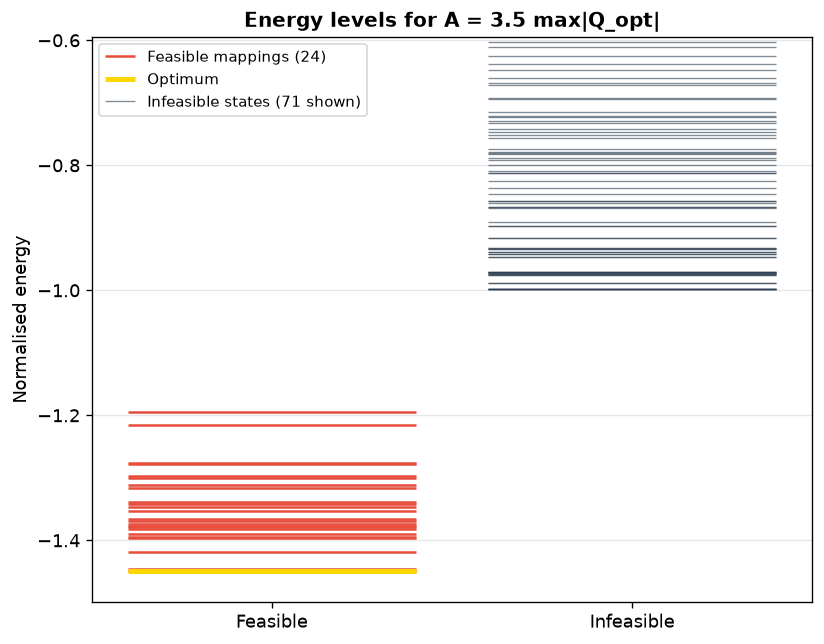

In [25]:
# Energy-level diagram: normalised energies of the feasible mappings and of the lowest infeasible states
e_inf = np.sort(E_ref[invalid_idx])
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.hlines(E_ref[valid_idx], 0.1, 0.9, color='#e74c3c', lw=1.5, label='Feasible mappings (24)')
ax.hlines(E_ref[opt_idx], 0.1, 0.9, color='gold', lw=3, label='Optimum')
shown = e_inf[e_inf < e_valid[-1] + 0.6]
ax.hlines(shown, 1.1, 1.9, color='#2c3e50', lw=0.8, alpha=0.6, label=f'Infeasible states ({len(shown)} shown)')
ax.set_xlim(0, 2); ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(['Feasible', 'Infeasible'])
ax.set_ylim(e_valid[0] - 0.05, e_valid[-1] + 0.6)
ax.set_ylabel('Normalised energy'); ax.grid(True, axis='y', alpha=0.3); ax.legend(fontsize=9, loc='upper left')
ax.set_title(f'Energy levels for A = {A_penalty/max_qopt:.1f} max|Q_opt|', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(FIGURE_DIR, 'fig_energy_levels_5f4l.png'), dpi=150, bbox_inches='tight')
plt.show()

*Figure 6. Normalised energies of the 24 feasible mappings and of the lowest infeasible states for $A = 3.5 \max|Q_{\text{opt}}|$. The feasible mappings form a narrow band well separated from the infeasible states.*

With $A = 3.5 \max|Q_{\text{opt}}|$ the normalisation constant is $2A = 7 \max|Q_{\text{opt}}|$, set by the off-diagonal penalty coefficients, so the largest objective coefficient becomes exactly $1/7 \approx 0.143$ after normalisation. The 24 feasible mappings span a normalised energy interval of about 0.25, and the optimum lies only 0.0021 below the second-best mapping, less than a third of the corresponding gap in the toy problem. The lowest infeasible state lies 0.45 above the optimum. As in the toy problem, the landscape seen by the circuit is dominated by the penalty: with angles $\gamma$ of order one, the phases of feasible and infeasible states differ substantially, whereas those of different feasible mappings are almost equal.

The smallest penalty weight that keeps the optimum as the ground state of the QUBO is $A_{\min} \approx 0.35 \max|Q_{\text{opt}}|$, so the value used in Sections 4 to 6 is ten times larger than necessary for correctness.

### 8.2 Why the XY ansatz does not move

We compare the optimised XY energies of Section 5 with the energy of the initial state, which is the mean energy of the 24 feasible mappings. We then repeat the optimisation at $p = 1$ and $p = 3$ with a fixed random generator and inspect the optimal mixing angles.

In [26]:
E_init_xy = float(np.mean(E_ref[valid_idx]))   # energy of the uniform superposition of feasible mappings
print(f'Energy of the XY initial state (uniform over the 24 feasible mappings): {E_init_xy:.4f}\n')
print(f'{"p":<4} {"E_XY":>9} {"E_XY - E_init":>14}')
for p in [1, 2, 3, 5, 8, 10]:
    r = qaoa_xy_results[p]
    print(f'p={p:<3} {r["energy"]:>9.4f} {r["energy"]-E_init_xy:>14.4f}')

# Seeded re-optimisation at small depth, to inspect the optimal mixing angles
rng_xy = np.random.default_rng(7)
config_reopt = {'problem': problem_fingerprint(Q), 'p_list': [1, 3], 'restarts': 15, 'maxiter': 800, 'seed': 7}
ck = load_checkpoint('xy_reopt', config_reopt)
xy_reopt = ck['results'] if ck else {}
if ck:
    rng_xy.bit_generator.state = ck['rng_state']
print(f'\n{"p":<4} {"E_XY":>9} {"P(valid)":>9}   beta_l mod pi')
for p in [1, 3]:
    if p not in xy_reopt:
        best = None
        for _ in range(15):
            res = minimize(qaoa_obj_xy, rng_xy.uniform(0, np.pi, 2*p), method='COBYLA',
                           options={'maxiter': 800, 'rhobeg': 0.5})
            if best is None or res.fun < best.fun:
                best = res
        xy_reopt[p] = {'energy': best.fun, 'params': best.x}
        save_checkpoint('xy_reopt', config_reopt, xy_reopt, rng_xy.bit_generator.state)
    r = xy_reopt[p]
    _, probs = run_qaoa_xy(r['params'])
    print(f'p={p:<3} {r["energy"]:>9.4f} {probs[valid_idx].sum():>9.3f}   {np.round(np.mod(r["params"][1::2], np.pi), 3)}')

Energy of the XY initial state (uniform over the 24 feasible mappings): -1.3463

p         E_XY  E_XY - E_init
p=1     -1.3463        -0.0000
p=2     -1.3465        -0.0002
p=3     -1.3493        -0.0031
p=5     -1.3517        -0.0054
p=8     -1.3110         0.0353
p=10    -1.2815         0.0648

p         E_XY  P(valid)   beta_l mod pi
p=1     -1.3463     1.000   [1.569]
p=3     -1.3503     0.998   [3.103 3.086 3.083]


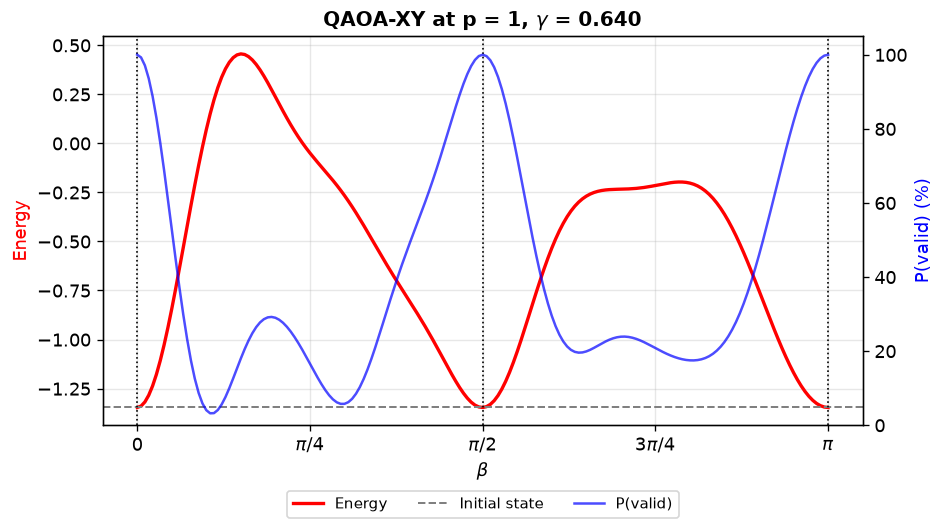

In [27]:
# XY ansatz at p = 1: energy and P(valid) as functions of beta, at the optimal gamma of the re-optimisation
gamma_1 = xy_reopt[1]['params'][0]
betas = np.linspace(0, np.pi, 181)
E_b, Pv_b = [], []
for b in betas:
    e, probs = run_qaoa_xy([gamma_1, b])
    E_b.append(e); Pv_b.append(probs[valid_idx].sum())
fig, ax1 = plt.subplots(figsize=(8, 4.6))
ax1.plot(betas, E_b, 'r-', lw=2, label='Energy')
ax1.axhline(E_init_xy, color='gray', ls='--', lw=1.2, label='Initial state')
ax1.set_xlabel(r'$\beta$'); ax1.set_ylabel('Energy', color='r')
ax2 = ax1.twinx(); ax2.plot(betas, 100 * np.array(Pv_b), 'b-', lw=1.5, alpha=0.7, label='P(valid)')
ax2.set_ylabel('P(valid) (%)', color='b'); ax2.set_ylim(0, 105)
for x in [0, np.pi / 2, np.pi]:
    ax1.axvline(x, color='black', ls=':', lw=1)
ax1.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi])
ax1.set_xticklabels(['0', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3); ax1.grid(True, alpha=0.3)
ax1.set_title(rf'QAOA-XY at p = 1, $\gamma$ = {gamma_1:.3f}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(FIGURE_DIR, 'fig_xy_beta_scan_5f4l.png'), dpi=150, bbox_inches='tight')
plt.show()

*Figure 7. Energy and probability of the feasible subspace of the XY ansatz at $p = 1$ as functions of the mixing angle, at the optimal $\gamma$ of the re-optimisation. The energy reaches its minimum, equal to the energy of the initial state, only at $\beta = 0$, $\pi/2$ and $\pi$, where the mixer is the identity or a permutation of the feasible mappings and $P(\text{valid}) = 100\%$. At all other angles leakage into infeasible states raises the energy.*

Up to $p = 5$ the optimised XY energies differ from the energy of the initial state, $-1.3463$, by less than 0.006; at $p = 8$ and $p = 10$ they are higher. The re-optimisation gives the same picture as in the toy problem: the optimal mixing angle is close to $\pi/2$ at $p = 1$ (1.569), and close to $\pi$ at $p = 3$ (3.103, 3.086 and 3.083), where each factor of the mixer reduces to a phase.

At $\beta = \pi/2$ each two-qubit factor of the mixer exchanges $|01\rangle$ and $|10\rangle$ up to a phase. The sequence of exchanges applied to each row is the same for all rows, so the full mixer relabels the pocket points and maps every feasible mapping onto another feasible mapping. The cell below verifies this numerically for $\beta = \pi/2$ and for $\beta = \pi$.

In [28]:
# At beta = pi/2 every two-qubit factor of the XY mixer maps |01> to -i|10> and |10> to -i|01>.
# We check that the full mixer then maps each feasible basis state onto a single feasible basis state.
for beta_test in [np.pi/2, np.pi]:
    images = []
    for idx in valid_idx:
        e = np.zeros(dim, dtype=complex); e[idx] = 1.0
        out = np.abs(apply_mixer_xy(e, beta_test))**2
        images.append((int(np.argmax(out)), out.max()))
    targets = {t for t, _ in images}
    print(f'beta = {beta_test:.4f}: max output probability on a single state = {min(w for _, w in images):.6f}, '
          f'{len(targets)} distinct images, all feasible: {targets <= set(valid_idx)}')

beta = 1.5708: max output probability on a single state = 1.000000, 24 distinct images, all feasible: True
beta = 3.1416: max output probability on a single state = 1.000000, 24 distinct images, all feasible: True


At both angles every feasible basis state is mapped onto a single feasible basis state, and the 24 images are distinct. The mixer then performs a permutation of the feasible mappings, or acts as the identity, and creates no superposition; the uniform initial state keeps a uniform probability distribution and its energy does not change.

For generic $\beta$ the mixer moves amplitude into non-injective states, which lie at least 0.45 above the optimum, while all feasible mappings lie within 0.25 of it (Section 8.1). The cost of leakage dominates the possible gain, and the optimiser converges to angles at which the mixer is effectively switched off. The values of $P(\text{valid})$ close to 100% found in Section 5 up to $p = 5$ are a consequence of this, not evidence that the ansatz explores the feasible subspace.

### 8.3 Penalty weight and selectivity

If the penalty scale is the limiting factor, reducing $A$ should increase $P(\text{opt} \mid \text{valid})$, at the cost of a lower $P(\text{valid})$, since infeasible states become cheaper. We test this with LR-QAOA, which is inexpensive at large depth, for $A/\max|Q_{\text{opt}}| \in \{3.5, 2.0, 1.0, 0.5\}$ and $p \in \{10, 20, 30\}$. All values are above $A_{\min}$, so the optimum remains the ground state in every case. The scan uses 30 random restarts of at most 500 COBYLA iterations and its own random generator. The columns `spread` and `gap_inf` report the normalised energy spread of the feasible mappings and the gap between the optimum and the lowest infeasible state.

In [29]:
def run_lr_scan(lr_params, p, energies):
    """LR-QAOA with the RX mixer for an arbitrary energy vector; returns (<H>, probabilities)."""
    g0, b0 = lr_params
    state = np.ones(dim, dtype=complex) / np.sqrt(dim)
    for k in range(1, p + 1):
        f = (2*k - 1) / (2*p)
        state = apply_mixer_rx(state * np.exp(-1j * g0 * f * energies), b0 * (1.0 - f))
    probs = np.abs(state)**2
    return float(probs @ energies), probs

rng = np.random.default_rng(2026)   # local generator: results do not depend on the cells above
A_factors = [3.5, 2.0, 1.0, 0.5]                 # A in units of max|Q_opt|; all above A_min
A_values = [f * max_qopt for f in A_factors]
p_values = [10, 20, 30]
n_restarts_scan = 30
config_scan = {'problem': problem_fingerprint(Q_opt_raw, Q_pen_raw), 'A_factors': A_factors,
               'p_values': p_values, 'restarts': n_restarts_scan, 'maxiter': 500, 'seed': 2026}
ck = load_checkpoint('penalty_scan', config_scan)
scan = ck['results'] if ck else {}
if ck:
    rng.bit_generator.state = ck['rng_state']
t0 = time.time()
print(f'{"A/max":>5} {"spread":>8} {"gap_inf":>8} {"p":>4} {"P(valid)":>9} {"P(opt)":>8} {"P(opt|valid)":>13}')
for f, A in zip(A_factors, A_values):
    E_A, _ = normalised_energies(A)
    ev = E_A[valid_idx]
    spread, gap_inf = ev.max() - ev.min(), E_A[invalid_idx].min() - ev.min()
    for p in p_values:
        if (f, p) in scan:
            s = scan[(f, p)]
            print(f'{f:>5.1f} {spread:>8.3f} {gap_inf:>8.3f} {p:>4d} {s["p_valid"]:>9.3f} {s["p_opt"]:>8.3f} {s["p_cond"]:>13.3f}')
            continue
        best = None
        for _ in range(n_restarts_scan):
            x0 = [rng.uniform(0, np.pi), rng.uniform(0, np.pi)]
            res = minimize(lambda x: run_lr_scan(x, p, E_A)[0], x0, method='COBYLA',
                           options={'maxiter': 500, 'rhobeg': 0.5})
            if best is None or res.fun < best.fun:
                best = res
        _, probs = run_lr_scan(best.x, p, E_A)
        p_val = probs[valid_idx].sum(); p_opt = probs[opt_idx]
        scan[(f, p)] = {'p_valid': p_val, 'p_opt': p_opt, 'p_cond': p_opt / p_val, 'params': best.x}
        save_checkpoint('penalty_scan', config_scan, scan, rng.bit_generator.state)
        print(f'{f:>5.1f} {spread:>8.3f} {gap_inf:>8.3f} {p:>4d} {p_val:>9.3f} {p_opt:>8.3f} {p_opt/p_val:>13.3f}')
print(f'\nTotal time: {time.time()-t0:.0f}s.  Uniform value of P(opt|valid): {1/24:.3f}')

A/max   spread  gap_inf    p  P(valid)   P(opt)  P(opt|valid)
  3.5    0.254    0.450   10     0.841    0.043         0.051
  3.5    0.254    0.450   20     0.973    0.054         0.056
  3.5    0.254    0.450   30     0.986    0.062         0.063
  2.0    0.445    0.413   10     0.764    0.045         0.059
  2.0    0.445    0.413   20     0.938    0.064         0.068
  2.0    0.445    0.413   30     0.942    0.087         0.092
  1.0    0.889    0.325   10     0.519    0.046         0.088
  1.0    0.889    0.325   20     0.693    0.084         0.122
  1.0    0.889    0.325   30     0.794    0.123         0.154
  0.5    1.779    0.151   10     0.180    0.052         0.287
  0.5    1.779    0.151   20     0.229    0.094         0.410
  0.5    1.779    0.151   30     0.304    0.143         0.472

Total time: 234s.  Uniform value of P(opt|valid): 0.042


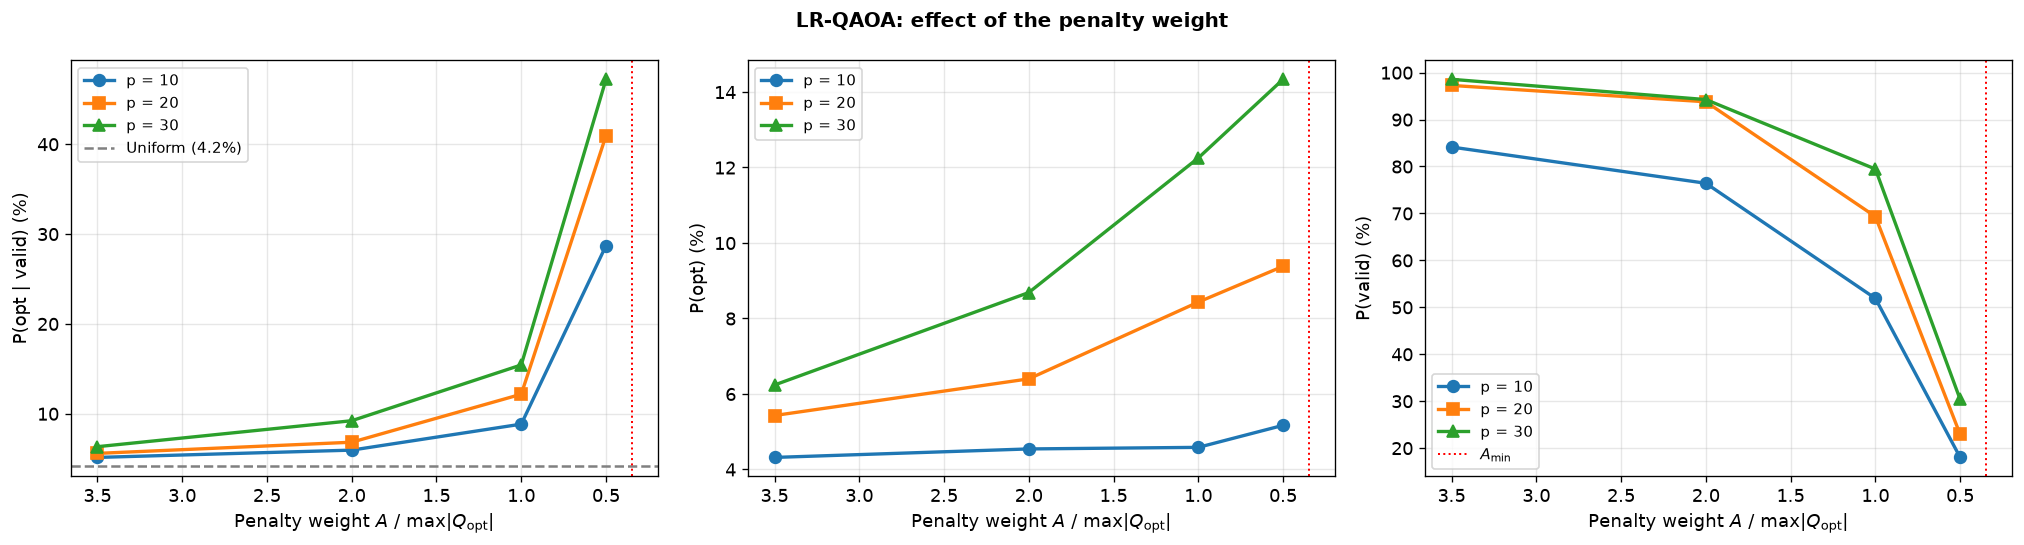

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
styles = {10: 'o-', 20: 's-', 30: '^-'}
for p in p_values:
    axes[0].plot(A_factors, [100 * scan[(A, p)]['p_cond'] for A in A_factors], styles[p], lw=2, ms=7, label=f'p = {p}')
    axes[1].plot(A_factors, [100 * scan[(A, p)]['p_opt'] for A in A_factors], styles[p], lw=2, ms=7, label=f'p = {p}')
    axes[2].plot(A_factors, [100 * scan[(A, p)]['p_valid'] for A in A_factors], styles[p], lw=2, ms=7, label=f'p = {p}')
axes[0].axhline(100 / n_feasible, color='gray', ls='--', label=f'Uniform ({100 / n_feasible:.1f}%)')
for ax, ylab in zip(axes, ['P(opt | valid) (%)', 'P(opt) (%)', 'P(valid) (%)']):
    ax.set_xlabel(r'Penalty weight $A$ / max$|Q_{\mathrm{opt}}|$'); ax.set_ylabel(ylab); ax.invert_xaxis()
    ax.axvline(A_min / max_qopt, color='red', ls=':', lw=1.2, label=r'$A_{\min}$' if ax is axes[2] else None)
    ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
fig.suptitle('LR-QAOA: effect of the penalty weight', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(FIGURE_DIR, 'fig_penalty_scan_5f4l.png'), dpi=150, bbox_inches='tight')
plt.show()

*Figure 8. LR-QAOA for decreasing penalty weight (the horizontal axis is reversed; the dotted line marks $A_{\min}$). Selectivity within the feasible subspace and the probability of the optimum increase as $A$ decreases, while the probability of the feasible subspace decreases.*

On this instance the effect is much stronger than in the toy problem. Reducing the penalty weight from $3.5$ to $0.5 \max|Q_{\text{opt}}|$ increases the spread of the feasible energies from 0.25 to 1.78, and at $p = 30$ $P(\text{opt} \mid \text{valid})$ increases from 6.3% to 47.2%, more than eleven times the uniform value. The price is a much lower $P(\text{valid})$, from 98.6% to 30.4%, because the gap to the lowest infeasible state shrinks from 0.45 to 0.15 as $A$ approaches $A_{\min}$. The probability of sampling the optimum, $P(\text{opt})$, increases from 6.2% to 14.3%. At fixed $A$, $P(\text{opt})$ and $P(\text{opt} \mid \text{valid})$ increase with depth.

The relevant figure of merit depends on how the circuit is used. If the output is sampled, infeasible bitstrings can be recognised and discarded classically at negligible cost, and the quantity that matters is $P(\text{opt})$, which more than doubles. The intermediate value $A = 1.0 \max|Q_{\text{opt}}|$ already doubles $P(\text{opt})$ while keeping $P(\text{valid})$ near 80%.

These results support the hypothesis of Section 8: at this size, the performance of the three variants is limited by the balance between penalty and objective, not by the depth of the circuits. A value of $A$ that only guarantees correctness, with a wide safety margin, is not a good value for QAOA. We note also that the optimiser minimises $\langle H \rangle$, which is dominated by the penalty, whereas the quantity of interest in practice is the probability of sampling the optimum.

## 9. Conclusions and next steps

Exhaustive enumeration identifies the optimal mapping, and simulated annealing reaches it in about two thirds of the runs. All three quantum variants concentrate amplitude on the feasible subspace, which is a necessary first step, but with $A = 3.5 \max|Q_{\text{opt}}|$ they hardly discriminate between feasible mappings. The analysis of Section 8 traces this to the energy scale of the penalty term, with the same mechanisms observed in the toy problem. The XY mixer, which preserves only the row constraint, is effectively switched off by the optimiser, and reducing $A$ towards its minimum admissible value increases the selectivity of LR-QAOA, here by a large factor, at the cost of feasibility. An earlier version of this notebook attributed the lack of improvement at larger depth to barren plateaus; at 12 qubits the evidence points instead to the formulation and to the classical optimiser.

The natural next steps are the following.

1. Replace the XY mixer with a mixer that preserves injectivity, such as the permutation mixers of [2], so that the column penalty is no longer needed.
2. Choose $A$ from the data, starting from $A_{\min}$, and select the margin by maximising $P(\text{opt})$ rather than $\langle H \rangle$.
3. Initialise each depth $p$ from the optimum at the previous depth, with the additional angles set to zero, which guarantees that the energy does not increase with depth.
4. Test non-variational schedules, in particular the bias-field digitized counterdiabatic algorithm (BF-DCQO) of Kipu Quantum, which Cadavid et al. [4] ran on IonQ trapped-ion hardware for portfolio optimisation.
5. Include the pharmacophore types in the objective, for example through compatibility weights between ligand and pocket points, and compare the resulting optimum with the crystallographic pose of 5F4L.

A hardware implementation would also require compiling the cost unitary into two-qubit $ZZ$ rotations, one for each non-zero off-diagonal QUBO coefficient, and the XY mixer into native gates, and would introduce sampling and gate noise, which are absent from this study.

## References

[1] Triuzzi et al., *Quantum Sci. Technol.* **10**, 045049 (2025).

[2] S. Hadfield, Z. Wang, B. O'Gorman, E. G. Rieffel, D. Venturelli and R. Biswas, "From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz", *Algorithms* **12**, 34 (2019).

[3] E. Farhi, J. Goldstone and S. Gutmann, "A Quantum Approximate Optimization Algorithm", arXiv:1411.4028 (2014).

[4] Cadavid et al., "Large-scale portfolio optimization on a trapped-ion quantum computer", arXiv:2602.23976 (2026).

[5] J. A. Montanez-Barrera and K. Michielsen, "Towards a universal QAOA protocol: evidence of a scaling advantage in solving some combinatorial optimization problems", arXiv:2405.09169 (2024).

[6] Q.-M. Ding, Y.-M. Huang and X. Yuan, "Molecular docking via quantum approximate optimization algorithm", *Phys. Rev. Applied* **21**, 034036 (2024), arXiv:2308.04098.

[7] B. Li, molecular-docking-qaoa, GitHub repository, github.com/25benjaminli/molecular-docking-qaoa.